# 🔥 Asistente Experto en Incendios Forestales en España
### Agente conversacional con Gemini, RAG y LangGraph

En este proyecto construyo un asistente de inteligencia artificial especializado en **incendios forestales en España**. Mi objetivo es que cualquier persona pueda hacerle preguntas en lenguaje natural sobre este tema y obtener respuestas precisas y fundamentadas en documentación real y datos oficiales, en lugar de depender únicamente del conocimiento general del modelo.

He elegido este dominio porque los incendios forestales son uno de los principales problemas medioambientales de España: cada verano afectan a miles de hectáreas, y la información sobre ellos (estadísticas, causas, grandes incendios, prevención y autoprotección) está repartida en informes técnicos extensos y en bases de datos poco accesibles para el público general. Un asistente capaz de consultar esas fuentes y responder de forma clara me parece una aplicación útil y realista de la IA Generativa.

## 📚 Base de conocimiento

He construido la base de conocimiento del asistente combinando dos tipos de fuentes que se complementan:

**1. Documentos PDF (información explicativa)**

| Documento | Fuente | Qué aporta |
|---|---|---|
| *Los Incendios Forestales en España. Decenio 2006-2015* | Ministerio de Agricultura, Pesca y Alimentación | Análisis de la evolución de los incendios, grandes incendios, causas, distribución territorial y temporal, extinción y prevención |
| *Metodología de la Estadística General de Incendios Forestales (EGIF)* | MITECO | Definición de las variables estadísticas y de las categorías de causa con las que se registra cada incendio |
| *Consejos ante Incendios Forestales* | Protección Civil – Ayuntamiento de Jerez | Recomendaciones de prevención y autoprotección para la ciudadanía |

**2. Dataset CSV (datos históricos)**

Un dataset con **296.839 incendios forestales registrados en España entre 1968 y 2022**, con información de superficie quemada, fecha, provincia, municipio, causa, víctimas, medios empleados y tiempos de extinción.

Como un registro numérico aislado aporta muy poco contexto a un modelo de lenguaje, no indexo el CSV fila a fila. En su lugar, lo preproceso con `pandas` para generar **textos descriptivos**: resúmenes por año, resúmenes por comunidad autónoma y fichas de los grandes incendios. De esta forma, el asistente puede responder tanto a preguntas explicativas (*¿por qué se producen?, ¿cómo protegerme?*) como a preguntas basadas en datos (*¿qué año ardió más superficie en Galicia?*).

## 🎯 Enfoque técnico

Para que el asistente responda con información fiable y trazable, combino tres piezas:

- **RAG (Retrieval-Augmented Generation):** antes de responder, el agente recupera los fragmentos más relevantes de mi base de conocimiento y los usa como contexto. Así reduzco las alucinaciones y puedo indicar de qué fuente procede cada respuesta.
- **Agente en LangGraph:** modelo el flujo como un grafo con nodos independientes (recuperar contexto → generar respuesta), lo que me permite controlar y visualizar cada paso.
- **Memoria de conversación:** el agente recuerda los turnos anteriores, de modo que puedo hacer preguntas de seguimiento como *"¿y cuántas hectáreas quemó ese incendio?"* sin repetir el contexto.

## 🛠️ Stack tecnológico

| Componente | Tecnología |
|---|---|
| LLM | Google Gemini (`ChatGoogleGenerativeAI`) |
| Embeddings | Google Gemini (`GoogleGenerativeAIEmbeddings`) |
| Base de conocimiento vectorial | ChromaDB |
| Framework del agente | LangGraph (sobre LangChain) |
| Preprocesado de datos | pandas |
| Entorno | Jupyter Notebook en VSCode |
| Interfaz web | Streamlit |

## 🗂️ Estructura del notebook

1. Introducción
2. Instalación, librerías y configuración de la API key
3. Carga y preprocesado de los documentos PDF
4. Preprocesado del dataset CSV con pandas
5. Creación de la base de conocimiento vectorial (ChromaDB + Gemini Embeddings)
6. Diseño del system prompt
7. Construcción del agente en LangGraph
8. Memoria de conversación
9. Batería de preguntas de ejemplo
10. Celda de chat interactiva
11. Conclusiones

# 2. Librerías y configuración de la API key

En esta sección preparo el entorno de trabajo: importo todas las librerías que voy a utilizar a lo largo del notebook, cargo de forma segura mi API key de Gemini desde un archivo `.env` y configuro los modelos de Gemini.

In [1]:
# Librerías generales
import os
import re
import time
import warnings
import pandas as pd
from dotenv import load_dotenv
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=DeprecationWarning)

# Carga y preparación de documentos
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document

# Gemini (LLM y embeddings) y base vectorial
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma

# Agente en LangGraph y memoria
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.memory import InMemorySaver

Centralizo aquí todas las importaciones del notebook, agrupadas según su función, para tener una visión clara de las herramientas que intervienen en el proyecto:

- **Generales:** `os` y `dotenv` para gestionar la API key y comprobar si existen carpetas, `re` para limpiar el texto extraído de los PDF, `time` para espaciar las llamadas a la API de embeddings, `pandas` para trabajar con el CSV e `Image`/`display` para visualizar el grafo del agente.
- **Documentos:** `PyPDFDirectoryLoader` carga de una vez todos los PDF de una carpeta, `RecursiveCharacterTextSplitter` los divide en fragmentos y `Document` me permite convertir los textos que genere a partir del CSV en el mismo formato que los PDF.
- **Gemini y ChromaDB:** `ChatGoogleGenerativeAI` es el modelo que genera las respuestas, `GoogleGenerativeAIEmbeddings` convierte los textos en vectores y `Chroma` es la base de datos vectorial donde los almaceno.
- **Agente:** los tipos de mensaje (`SystemMessage`, `HumanMessage`, `AIMessage`), los componentes del grafo de LangGraph (`StateGraph`, `MessagesState`, `START`, `END`) y `InMemorySaver`, que me servirá para dotar al agente de memoria.

In [2]:
load_dotenv()
API_KEY = os.getenv("GEMINI_API_KEY")

print("API Key cargada:", "✅" if API_KEY else "❌ No encontrada")

API Key cargada: ✅


In [3]:
MODEL = "gemini-3.5-flash-lite"
MODEL_EMBEDDING = "gemini-embedding-2"

RUTA_PDFS = "data/incendios"
RUTA_CSV = "data/fires-all.csv"
RUTA_CHROMA = "data/chroma_incendios"

llm = ChatGoogleGenerativeAI(model=MODEL, google_api_key=API_KEY)
embeddings = GoogleGenerativeAIEmbeddings(model=MODEL_EMBEDDING, api_key=API_KEY)

print("✅ LLM y modelo de embeddings configurados")

✅ LLM y modelo de embeddings configurados


Defino en un único lugar los parámetros principales del proyecto, de forma que si quiero cambiar de modelo o de carpeta solo tengo que modificarlo aquí:

- **`MODEL`:** utilizo `gemini-3.5-flash-lite`, un modelo de la familia más reciente de Gemini, rápido y económico. En un sistema RAG el peso de la respuesta recae en el contexto recuperado, por lo que no necesito un modelo más grande para redactar respuestas precisas; además, al ser más ligero, consume menos cuota de la API y responde con menor latencia, algo importante en una conversación.
- **`MODEL_EMBEDDING`:** `gemini-embedding-2` es el modelo de Gemini que transforma cada fragmento de texto en un vector numérico.
- **Rutas:** la carpeta con los PDF, el archivo CSV y la carpeta donde ChromaDB guardará la base vectorial en disco.

No modifico la **temperatura** del modelo porque los modelos de la familia Gemini 3.5 utilizan unos parámetros de muestreo fijos que no pueden ajustarse (si se indica una temperatura, el modelo la ignora). En lugar de depender de la temperatura, controlo la precisión y la fidelidad de las respuestas mediante el system prompt, en el que obligo al modelo a responder únicamente con la información recuperada (sección 6).

In [4]:
respuesta_prueba = llm.invoke("Responde en una sola frase: ¿qué es un incendio forestal?")
print(respuesta_prueba.text)

Un incendio forestal es un fuego no planificado ni controlado que se propaga rápidamente a través de la vegetación en áreas rurales o forestales, destruyendo la flora, la fauna y poniendo en peligro vidas y bienes.


Hago una llamada de prueba al LLM para verificar que la conexión con Gemini funciona correctamente antes de empezar a construir la base de conocimiento. Para leer la respuesta utilizo el atributo `.text` en lugar de `.content`: los modelos de la familia Gemini 3 pueden devolver el contenido como una lista de bloques, y `.text` me garantiza obtener siempre el texto limpio, independientemente del formato interno del mensaje.

# 3. Carga y preprocesado de los documentos PDF

En esta sección cargo los tres documentos PDF de mi base de conocimiento, reviso su contenido, limpio el ruido propio de la extracción de texto de un PDF (números de página sueltos, palabras partidas, saltos de línea y espacios innecesarios) y, por último, divido el texto en fragmentos (*chunks*) de un tamaño adecuado para la búsqueda semántica.

In [5]:
loader = PyPDFDirectoryLoader(RUTA_PDFS)
paginas = loader.load()

print(f"Páginas cargadas en total: {len(paginas)}\n")
print("Páginas por documento:")
print(pd.Series([os.path.basename(p.metadata["source"]) for p in paginas]).value_counts().to_string())

Páginas cargadas en total: 182

Páginas por documento:
incendios-decenio-2006-2015_tcm30-521617.pdf    166
Estadística-General-IF-Metodología.pdf           14
Consejos_Incendios_Forestales.pdf                 2


Utilizo `PyPDFDirectoryLoader` para cargar de una sola vez todos los PDF de la carpeta `data/incendios`. El cargador devuelve una lista de objetos `Document`, uno por cada página, que contienen el texto extraído (`page_content`) y unos metadatos con la ruta del archivo de origen (`source`) y el número de página (`page`).

Muestro cuántas páginas aporta cada documento para comprobar que se han leído los tres archivos correctamente.

In [6]:
pagina_ejemplo = paginas[26]

print(f"Documento: {os.path.basename(pagina_ejemplo.metadata['source'])} | Página: {pagina_ejemplo.metadata['page'] + 1}")
print("-" * 80)
print(pagina_ejemplo.page_content[:1000])

Documento: incendios-decenio-2006-2015_tcm30-521617.pdf | Página: 11
--------------------------------------------------------------------------------
[ 5 ]
CAP
02
1 Dentro de los siniestros la Estadística General de Incendios Forestales distingue aquellos que afectan a una superficie 
≤ 1 hectárea, llamados conatos, de los que afectan a superficies > 1 hectárea, que reciben el nombre de incendios.
   La ocurrencia de los incendios forestales se suele caracterizar por su régimen, entendido 
como el patrón de distribución espacial y temporal del fuego y de sus efectos. Así el régimen 
de incendios se define por diversas variables, entre las que destacan típicamente la frecuencia 
(número de incendios en un periodo de tiempo), afección, recurrencia o severidad, entre 
otros. El régimen de incendios depende fundamentalmente de tres factores principales que lo 
condicionan: el clima, los combustibles y las fuentes de ignición.
El primer factor es determinante, al condicionar en buena medida

Antes de limpiar nada, inspecciono el texto en bruto de una página para identificar qué tipo de ruido introduce la extracción. En los PDF es habitual encontrar saltos de línea en mitad de las frases, palabras partidas con guion al final de una línea, números de página aislados y espacios duplicados. Este ruido no aporta significado y empeora la calidad de los embeddings, por lo que conviene eliminarlo.

In [7]:
def limpiar_texto(texto: str) -> str:
    """Elimina el ruido típico de la extracción de texto de un PDF"""
    texto = re.sub(r"([a-záéíóúñ])-\n([a-záéíóúñ])", r"\1\2", texto)    # Vuelvo a unir palabras partidas con guion
    texto = re.sub(r"\[\s*\d+\s*\]", "", texto)     # Elimino los números de página entre corchetes, como "[ 5 ]"
    lineas = [linea.strip() for linea in texto.split("\n")]
    lineas = [linea for linea in lineas if linea and not linea.isdigit() and linea != "CAP"]   # Descarto líneas vacías, números de página y la cabecera "CAP"
    texto = " ".join(lineas)
    texto = re.sub(r"\s+", " ", texto)
    return texto.strip()

LONGITUD_MINIMA = 100

paginas_limpias = []
for pagina in paginas:
    texto_limpio = limpiar_texto(pagina.page_content)

    # Descarto portadas, páginas en blanco o páginas que solo contienen imágenes
    if len(texto_limpio) < LONGITUD_MINIMA:
        continue

    paginas_limpias.append(Document(
        page_content=texto_limpio,
        metadata={
            "fuente": os.path.basename(pagina.metadata["source"]),
            "pagina": pagina.metadata["page"] + 1,
            "tipo": "pdf"
        }
    ))

print(f"Páginas originales: {len(paginas)}")
print(f"Páginas tras la limpieza: {len(paginas_limpias)}")
print(f"Páginas descartadas: {len(paginas) - len(paginas_limpias)}")

Páginas originales: 182
Páginas tras la limpieza: 176
Páginas descartadas: 6


Defino la función `limpiar_texto`, que aplica cuatro transformaciones a cada página:

1. **Une las palabras partidas con guion** al final de una línea (por ejemplo, *"pre-\nvención"* → *"prevención"*). Solo lo aplico entre letras minúsculas para no alterar rangos de años como *"2006-2015"*.
2. **Elimina la cabecera de maquetación** que el informe del Decenio repite en cada página: el número de página entre corchetes (*"[ 5 ]"*), la palabra *"CAP"* y el número de capítulo. Al inspeccionar el texto en bruto detecté que esta cabecera aparecía al inicio de cada página y, si no la quitaba, se colaría como ruido en muchos fragmentos.
3. **Elimina las líneas vacías y los números de página aislados**, y une el resto de líneas con un espacio, ya que en un PDF los saltos de línea dependen de la maquetación y no del significado.
4. **Normaliza los espacios**, sustituyendo cualquier secuencia de espacios o tabulaciones por uno solo.

Después recorro todas las páginas y descarto aquellas que, una vez limpias, tienen menos de 100 caracteres: suelen ser portadas, páginas en blanco o páginas formadas solo por gráficos, que no aportan información útil a la búsqueda.

Con el texto limpio creo nuevos objetos `Document` con unos **metadatos más claros**: el nombre del archivo (`fuente`), el número de página empezando en 1 (`pagina`) y el tipo de fuente (`tipo`). Estos metadatos me permitirán más adelante que el agente indique de qué documento y página procede cada respuesta.

In [8]:
print("TEXTO ORIGINAL")
print("-" * 80)
print(paginas[26].page_content[:600])

print("\nTEXTO LIMPIO")
print("-" * 80)
pagina_limpia = next(p for p in paginas_limpias if p.metadata["fuente"] == os.path.basename(paginas[26].metadata["source"])
                     and p.metadata["pagina"] == paginas[26].metadata["page"] +1)   # Busco la misma página ya limpia
print(pagina_limpia.page_content[:600])

TEXTO ORIGINAL
--------------------------------------------------------------------------------
[ 5 ]
CAP
02
1 Dentro de los siniestros la Estadística General de Incendios Forestales distingue aquellos que afectan a una superficie 
≤ 1 hectárea, llamados conatos, de los que afectan a superficies > 1 hectárea, que reciben el nombre de incendios.
   La ocurrencia de los incendios forestales se suele caracterizar por su régimen, entendido 
como el patrón de distribución espacial y temporal del fuego y de sus efectos. Así el régimen 
de incendios se define por diversas variables, entre las que destacan típicamente la frecuencia 
(número de incendios en un periodo de tiempo), afección, recurr

TEXTO LIMPIO
--------------------------------------------------------------------------------
1 Dentro de los siniestros la Estadística General de Incendios Forestales distingue aquellos que afectan a una superficie ≤ 1 hectárea, llamados conatos, de los que afectan a superficies > 1 hectárea, que rec

Comparo la misma página antes y después de la limpieza para verificar que el texto resultante es continuo y legible, sin saltos de línea artificiales ni números de página sueltos, y que no he perdido contenido relevante en el proceso.

In [9]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1500,
    chunk_overlap=200
)

chunks_pdf = text_splitter.split_documents(paginas_limpias)

longitudes = pd.Series([len(c.page_content) for c in chunks_pdf])

print(f"Chunks generados: {len(chunks_pdf)}")
print(f"Longitud media: {longitudes.mean():.0f} caracteres | mínima: {longitudes.min()} | máxima: {longitudes.max()}\n")
print("Chunks por documento:")
print(pd.Series([c.metadata["fuente"] for c in chunks_pdf]).value_counts().to_string())

Chunks generados: 379
Longitud media: 1134 caracteres | mínima: 138 | máxima: 1500

Chunks por documento:
incendios-decenio-2006-2015_tcm30-521617.pdf    348
Estadística-General-IF-Metodología.pdf           28
Consejos_Incendios_Forestales.pdf                 3


Divido las páginas limpias en fragmentos con `RecursiveCharacterTextSplitter`, que intenta cortar primero por párrafos, después por frases y, en último caso, por palabras, de manera que los fragmentos respeten en lo posible las unidades de significado.

He elegido estos parámetros:

- **`chunk_size=1500`:** los documentos son informes técnicos con párrafos largos que suelen combinar una explicación con varias cifras. Con fragmentos de 1.500 caracteres cada chunk conserva una idea completa junto a sus datos, sin llegar a mezclar temas distintos.
- **`chunk_overlap=200`:** cada fragmento comparte unos 200 caracteres con el anterior, para que una frase que quede cortada en el límite entre dos chunks siga apareciendo completa en al menos uno de ellos.

Finalmente, compruebo el número total de fragmentos, su longitud media y cuántos aporta cada documento. Cada chunk hereda automáticamente los metadatos de la página de la que procede.

In [10]:
chunk_ejemplo = chunks_pdf[28]

print(f"Metadatos: {chunk_ejemplo.metadata}")
print("-" * 80)
print(chunk_ejemplo.page_content)

Metadatos: {'fuente': 'Estadística-General-IF-Metodología.pdf', 'pagina': 14, 'tipo': 'pdf'}
--------------------------------------------------------------------------------
, , , , 6. Factores para cálculo de pérdidas en productos maderables o repoblaciones: Especie Especie Especie Ve = Vol. maderable con aprovechamiento comercial dañado por el fuego de L-F (m3).. V'e = Vol. maderable que se puede aprovechar del Latizal-Fustal (m3)...................................... Vm = Vol. maderable con aprovechamiento comercial dañado por fuego del Fustal (m3)........... V'm = Vol. maderabe dañado por el fuego que se puede aprovechar del Fustal (m3)................... Pe = Precio medio del m3 de madera Latizal-Fustal (euros)...................................................... , P'e = Precio medio del m3 de madera quemada de Latizal-Fustal (euros)................................... , Pm = Precio medio del m3 de madera en pie con corteza del Fustal (euros)............................... , P'm =

# 4. Preprocesado del dataset CSV con pandas

En esta sección transformo el dataset histórico de incendios forestales en documentos de texto que mi asistente pueda aprovechar. Un registro como *"3,5 ha, provincia 29, causa 5"* apenas tiene significado para un modelo de lenguaje y, además, indexar casi 300.000 filas de forma individual sería lento, costoso y poco útil: la búsqueda semántica solo recupera unos pocos fragmentos, por lo que nunca podría responder a preguntas que requieren agregar todo el dataset.

Por ello sigo este proceso:

1. Cargo e inspecciono el CSV.
2. Limpio los datos y traduzco los códigos numéricos a nombres comprensibles.
3. Verifico el significado de los códigos de causa.
4. Genero cuatro tipos de documentos descriptivos: un resumen general, resúmenes por año, resúmenes por comunidad autónoma y fichas de los grandes incendios.

In [11]:
df_raw = pd.read_csv(RUTA_CSV)

print(f"Registros: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Registros: 296,839 | Columnas: 21


,id,superficie,fecha,lat,lng,latlng_explicit,idcomunidad,idprovincia,idmunicipio,municipio,...,causa_supuesta,causa_desc,muertos,heridos,time_ctrl,time_ext,personal,medios,gastos,perdidas
0,1968290001,14.0,1968-01-01,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,40,0,0,NaN,360.0,0,0,0.0,0.0
1,1968430003,3.0,1968-01-03,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,0,0,0,NaN,60.0,0,0,0.0,0.0
2,1968290006,2.0,1968-01-06,NaN,NaN,NaN,4,29,0,INDETERMINADO,...,1,0,0,0,NaN,120.0,0,0,0.0,0.0
3,1968120007,8.2,1968-01-07,NaN,NaN,NaN,9,12,0,INDETERMINADO,...,1,20,0,0,NaN,120.0,0,0,0.0,0.0
4,1968430016,600.0,1968-01-07,NaN,NaN,NaN,2,43,0,INDETERMINADO,...,1,20,0,0,NaN,1440.0,35,1,0.0,0.0


Cargo el CSV con `pd.read_csv` y muestro sus dimensiones y las primeras filas. El dataset contiene casi 300.000 incendios con 21 columnas, entre las que destacan la superficie quemada, la fecha, la comunidad autónoma, la provincia, el municipio, la causa, el número de víctimas, el personal de extinción y el tiempo hasta la extinción. Observo que la comunidad, la provincia y la causa están codificadas con números, por lo que tendré que traducirlas.

In [12]:
porcentaje_nulos = (df_raw.isna().mean() * 100).round(1)

print("Porcentaje de valores nulos por columna:")
print(porcentaje_nulos[porcentaje_nulos > 0].to_string())

Porcentaje de valores nulos por columna:
lat                18.3
lng                18.3
latlng_explicit    18.3
time_ctrl          51.8


Reviso la calidad de los datos calculando el porcentaje de valores nulos de cada columna y muestro solo las que tienen alguno. Las columnas afectadas son las coordenadas (`lat`, `lng`) y el tiempo hasta el control del incendio (`time_ctrl`), que no voy a utilizar en los documentos. Las columnas que sí necesito (superficie, fecha, ubicación, causa, víctimas y tiempo de extinción) están prácticamente completas.

In [13]:
PROVINCIAS = {
    1: "Álava", 2: "Albacete", 3: "Alicante", 4: "Almería", 5: "Ávila", 6: "Badajoz",
    7: "Illes Balears", 8: "Barcelona", 9: "Burgos", 10: "Cáceres", 11: "Cádiz", 12: "Castellón",
    13: "Ciudad Real", 14: "Córdoba", 15: "A Coruña", 16: "Cuenca", 17: "Girona", 18: "Granada",
    19: "Guadalajara", 20: "Gipuzkoa", 21: "Huelva", 22: "Huesca", 23: "Jaén", 24: "León",
    25: "Lleida", 26: "La Rioja", 27: "Lugo", 28: "Madrid", 29: "Málaga", 30: "Murcia",
    31: "Navarra", 32: "Ourense", 33: "Asturias", 34: "Palencia", 35: "Las Palmas", 36: "Pontevedra",
    37: "Salamanca", 38: "Santa Cruz de Tenerife", 39: "Cantabria", 40: "Segovia", 41: "Sevilla", 42: "Soria",
    43: "Tarragona", 44: "Teruel", 45: "Toledo", 46: "Valencia", 47: "Valladolid", 48: "Bizkaia",
    49: "Zamora", 50: "Zaragoza", 51: "Ceuta", 52: "Melilla"
}

COMUNIDADES = {
    1: "País Vasco", 2: "Cataluña", 3: "Galicia", 4: "Andalucía", 5: "Principado de Asturias",
    6: "Cantabria", 7: "La Rioja", 8: "Región de Murcia", 9: "Comunitat Valenciana", 10: "Aragón",
    11: "Castilla-La Mancha", 12: "Canarias", 13: "Comunidad Foral de Navarra", 14: "Extremadura",
    15: "Illes Balears", 16: "Comunidad de Madrid", 17: "Castilla y León", 18: "Ceuta"
}

CAUSAS = {
    1: "rayo", 2: "negligencia", 3: "accidente",
    4: "intencionado", 5: "desconocida", 6: "incendio reproducido"
}

SUBCAUSAS = {
    # Negligencias (código de causa 2)
    210: "quema agrícola", 211: "quema de rastrojos", 212: "quema de restos de poda",
    213: "quema de lindes y bordes de fincas", 214: "quema de bordes de acequias", 215: "quema agrícola",
    220: "quema para regenerar pastos", 221: "quema de matorral para regenerar pastos",
    222: "quema de herbáceas para regenerar pastos", 223: "quema para regenerar pastos",
    230: "trabajos forestales", 240: "hogueras", 250: "fumadores", 260: "quema de basura",
    270: "escape de vertedero", 280: "quema de matorral", 281: "quema de matorral próximo a edificaciones",
    282: "quema de matorral para limpieza de caminos o sendas", 283: "quema de matorral en focos de animales nocivos",
    284: "quema de matorral", 286: "limpieza de infraestructuras de riego (acequias, cavas, etc.)",
    291: "actividades apícolas", 292: "fuegos artificiales", 293: "globos", 294: "juegos de niños",
    295: "restos de poda de urbanización", 296: "empleo de explosivos",
    # Accidentes (código de causa 3)
    302: "caza", 310: "ferrocarril", 320: "líneas eléctricas", 330: "motores y máquinas",
    331: "motores y máquinas", 332: "motores y máquinas", 333: "motores y máquinas",
    334: "motores y máquinas", 335: "motores y máquinas", 336: "accidentes de vehículos",
    340: "maniobras militares",
    # Motivaciones de los incendios intencionados (código de causa 4)
    41: "campesinos para eliminar matorral y residuos agrícolas", 42: "pastores y ganaderos para regenerar el pasto",
    43: "venganzas", 44: "ahuyentar animales (lobos, jabalíes)", 45: "cazadores para facilitar la caza",
    46: "contra el acotamiento de la caza", 47: "disensiones sobre la titularidad de los montes públicos o privados",
    48: "represalia por la reducción de las inversiones públicas en los montes",
    49: "obtener salarios en la extinción o en la restauración", 410: "pirómanos",
    411: "bajar el precio de la madera", 412: "modificación en el uso del suelo",
    413: "grupos políticos para crear malestar social", 414: "animadversión contra repoblaciones forestales",
    415: "delincuentes para distraer a la Guardia Civil o a la Policía",
    416: "rechazo a la creación o existencia de espacios naturales protegidos",
    417: "ritos pseudorreligiosos y satanismo", 418: "contemplar las labores de extinción", 419: "vandalismo",
    420: "favorecer la producción de productos del monte", 421: "forzar resoluciones de consorcios o convenios",
    422: "resentimiento por expropiaciones", 423: "venganzas por multas impuestas",
    424: "mantenimiento tradicional del bosque", 425: "limpieza de vegetación fronteriza"
}

MESES = {
    1: "enero", 2: "febrero", 3: "marzo", 4: "abril", 5: "mayo", 6: "junio",
    7: "julio", 8: "agosto", 9: "septiembre", 10: "octubre", 11: "noviembre", 12: "diciembre"
}

Defino los diccionarios que me permiten traducir los códigos numéricos del dataset a nombres legibles. Para construirlos me he apoyado en el archivo de códigos `eell-extra-codes.xlsx`, que acompaña al dataset y que guardo en la carpeta `data/` como fuente de referencia:

- **`PROVINCIAS`:** el dataset utiliza los códigos oficiales del INE, que asocio a su nombre.
- **`COMUNIDADES`:** el dataset usa una numeración propia, distinta de la del INE. La he deducido agrupando las provincias que pertenecen a cada código (por ejemplo, el código 3 agrupa Ourense, Pontevedra, Lugo y A Coruña, por lo que corresponde a Galicia), y he comprobado con el archivo de códigos que cada provincia pertenece a la comunidad asignada.
- **`CAUSAS`:** las seis categorías de causa de la Estadística General de Incendios Forestales. El archivo de códigos confirma su significado; agrupa los códigos 2 y 3 como *"accidente o negligencia"*, pero sus subcausas permiten distinguirlos: las del grupo 2 son negligencias (quemas, fumadores, hogueras…) y las del grupo 3 son accidentes (ferrocarril, líneas eléctricas, motores…).
- **`SUBCAUSAS`:** el detalle de cada causa. Para las negligencias y los accidentes indica el origen concreto del fuego, y para los incendios intencionados indica la **motivación**. He trasladado los códigos del archivo de referencia a este diccionario, unificando las etiquetas que aparecían duplicadas con redacciones distintas.
- **`MESES`:** para expresar las fechas en lenguaje natural dentro de los documentos.

He preferido escribir los códigos como diccionarios de Python en lugar de cargar el Excel desde el notebook porque son pocos valores, la hoja original contiene filas de comentarios y códigos repetidos que habría que limpiar, y de esta forma el notebook es autocontenido.

In [14]:
df = df_raw.copy()

df["fecha"] = pd.to_datetime(df["fecha"])
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
df["decada"] = (df["anio"] // 10) * 10

df = df[df["anio"] <= 2022].copy()  # No utilizo los datos de 2023 porque estan incompletos

df["provincia"] = df["idprovincia"].map(PROVINCIAS)
df["comunidad"] = df["idcomunidad"].map(COMUNIDADES)
df["causa_nombre"] = df["causa"].map(CAUSAS)

codigo_subcausa = (df["causa"].astype(str) + df["causa_desc"].astype(str)).astype(int)  # Uno causa y subcausa: 2 y 50 -> 250
df["subcausa"] = codigo_subcausa.map(SUBCAUSAS).fillna("sin especificar")

df.loc[df["municipio"] == "INDETERMINADO", "municipio"] = "municipio no registrado"
df["duracion_horas"] = (df["time_ext"] / 60).round(1)

df = df[["fecha", "anio", "mes", "decada", "superficie", "comunidad", "provincia", "municipio", "causa_nombre", "subcausa", "muertos",
         "heridos", "personal", "duracion_horas"]]

print(f"Registros tras la limpieza: {len(df):,} ({df['anio'].min()}-{df['anio'].max()})")
print("Códigos sin traducir:", df[["provincia", "comunidad", "causa_nombre"]].isna().sum().to_dict())
df.head()

Registros tras la limpieza: 296,816 (1968-2022)
Códigos sin traducir: {'provincia': 0, 'comunidad': 0, 'causa_nombre': 0}


,fecha,anio,mes,decada,superficie,comunidad,provincia,municipio,causa_nombre,subcausa,muertos,heridos,personal,duracion_horas
0,1968-01-01,1968,1,1960,14.0,Andalucía,Málaga,municipio no registrado,negligencia,hogueras,0,0,0,6.0
1,1968-01-03,1968,1,1960,3.0,Cataluña,Tarragona,municipio no registrado,desconocida,sin especificar,0,0,0,1.0
2,1968-01-06,1968,1,1960,2.0,Andalucía,Málaga,municipio no registrado,desconocida,sin especificar,0,0,0,2.0
3,1968-01-07,1968,1,1960,8.2,Comunitat Valenciana,Castellón,municipio no registrado,accidente,líneas eléctricas,0,0,0,2.0
4,1968-01-07,1968,1,1960,600.0,Cataluña,Tarragona,municipio no registrado,accidente,líneas eléctricas,0,0,35,24.0


Realizo la limpieza y transformación del dataset sobre una copia, para conservar intactos los datos originales:

- **Fechas:** convierto la columna `fecha` a tipo fecha con `pd.to_datetime` y extraigo el año, el mes y la década, que usaré para agrupar los datos.
- **Año 2023:** lo descarto porque solo contiene una veintena de registros sueltos; incluirlo como un año más daría la falsa impresión de que en 2023 apenas hubo incendios.
- **Traducción de códigos:** con `.map` sustituyo los códigos de provincia, comunidad y causa por sus nombres.
- **Subcausas:** en el dataset, el código detallado de la causa está dividido en dos columnas (`causa` y `causa_desc`). Las uno como texto para reconstruir el código completo que aparece en el archivo de referencia (por ejemplo, causa 2 y subcausa 50 forman el código 250, *"fumadores"*) y lo traduzco con el diccionario `SUBCAUSAS`. Cuando el código no tiene una descripción asociada, lo marco como *"sin especificar"*.
- **Municipios:** sustituyo el valor `INDETERMINADO` por *"municipio no registrado"*, una expresión más clara para el modelo.
- **Duración:** paso el tiempo de extinción de minutos a horas, una unidad más fácil de interpretar.
- **Selección de columnas:** me quedo solo con las columnas que voy a utilizar.

Por último, compruebo que ningún código de provincia, comunidad o causa ha quedado sin traducir.

In [15]:
print("Distribución de causas en todo el periodo (%):")
print((df["causa_nombre"].value_counts(normalize=True) * 100).round(1).to_string())

cobertura = pd.DataFrame({"causa": df["causa_nombre"], "subcausa_conocida": df["subcausa"] != "sin especificar"})

print("\nPorcentaje de incendios con subcausa identificada:")
print((cobertura.groupby("causa")["subcausa_conocida"].mean() * 100).round(1).sort_values(ascending=False).to_string())

Distribución de causas en todo el periodo (%):
causa_nombre
intencionado            51.7
desconocida             26.8
negligencia             15.3
accidente                3.3
rayo                     2.2
incendio reproducido     0.6

Porcentaje de incendios con subcausa identificada:
causa
accidente               83.2
negligencia             83.0
intencionado            40.1
desconocida              0.0
incendio reproducido     0.0
rayo                     0.0


Compruebo el resultado de la traducción de las causas y de las subcausas:

1. **Distribución de causas:** los incendios intencionados son la causa mayoritaria en España, seguidos de los de causa desconocida y de las negligencias, lo cual es coherente con lo que describe el informe del Decenio 2006-2015.
2. **Cobertura de las subcausas:** consigo identificar la subcausa concreta en más del 80 % de las negligencias y los accidentes, y en torno al 40 % de los incendios intencionados; en el resto de intencionados la motivación no llegó a determinarse y figura como no especificada. Como era de esperar, los incendios por rayo, de causa desconocida o reproducidos no tienen subcausa, ya que la estadística oficial no la contempla para estas categorías.

Esta información me permite que el asistente no solo responda cuántos incendios hubo de cada tipo, sino también **por qué** se produjeron.

In [16]:
def fmt(numero, decimales=0):
    """Formatea un número con punto de miles y coma decimal al estilo español"""
    texto = f"{numero:,.{decimales}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")  # Intercambio los separadores al formato español

def top_texto(serie, unidad="", decimales=0):
    """Convierte una Serie en una enumeración legible"""
    if len(serie) == 0:
        return "sin datos"
    return ", ".join(f"{etiqueta} ({fmt(valor, decimales)}{unidad})" for etiqueta, valor in serie.items())

def describir_incendio(fila):
    """Describe en una frase un incendio concreto a partir de su fila"""
    return (f"el {fila['fecha'].day} de {MESES[fila['fecha'].month]} de {fila['fecha'].year} "
            f"en {fila['municipio']} ({fila['provincia']}, {fila['comunidad']}), "
            f"con {fmt(fila['superficie'], 1)} hectáreas quemadas (causa: {fila['causa_nombre']})")

print(fmt(1234567.891, 1))

1.234.567,9


Defino tres funciones auxiliares que reutilizo al generar todos los documentos:

- **`fmt`:** formatea los números al estilo español (punto para los miles y coma para los decimales, por ejemplo *1.234.567,9*). Como los documentos están en español, mantener este formato evita confusiones al modelo y al lector.
- **`top_texto`:** convierte un ranking calculado con pandas en una enumeración legible, por ejemplo *"Galicia (1.970.436 ha), Castilla y León (1.521.215 ha)"*. Si el ranking está vacío (por ejemplo, una comunidad sin incendios intencionados con motivación conocida), devuelve *"sin datos"* para que el texto siga siendo coherente.
- **`describir_incendio`:** redacta en una frase los datos clave de un incendio concreto: fecha, ubicación, superficie y causa.

In [17]:
ANIO_INICIO, ANIO_FIN = df["anio"].min(), df["anio"].max()
UMBRAL_GRAN_INCENDIO = 500

superficie_por_anio = df.groupby("anio")["superficie"].sum()
superficie_por_comunidad = df.groupby("comunidad")["superficie"].sum().sort_values(ascending=False)
causas = df.groupby("causa_nombre")["superficie"].agg(["count", "sum"]).sort_values("count", ascending=False)
decadas = df.groupby("decada")["superficie"].agg(["count", "sum"])
mayor_incendio = df.loc[df["superficie"].idxmax()]

intencionados = df[(df["causa_nombre"] == "intencionado") & (df["subcausa"] != "sin especificar")]
negligencias_accidentes = df[((df["causa_nombre"] == "negligencia") | (df["causa_nombre"] == "accidente"))
                             & (df["subcausa"] != "sin especificar")]

texto_general = (
    f"RESUMEN GENERAL DE LOS INCENDIOS FORESTALES EN ESPAÑA ({ANIO_INICIO}-{ANIO_FIN}).\n"
    f"Entre {ANIO_INICIO} y {ANIO_FIN} se registraron en España {fmt(len(df))} incendios forestales "
    f"de al menos 1 hectárea, que quemaron en total {fmt(df['superficie'].sum())} hectáreas. "
    f"De ellos, {fmt((df['superficie'] >= UMBRAL_GRAN_INCENDIO).sum())} fueron grandes incendios forestales "
    f"(500 hectáreas o más). En total causaron {fmt(df['muertos'].sum())} muertos y {fmt(df['heridos'].sum())} heridos.\n"
    f"Incendios y superficie quemada por causa: "
    + "; ".join(f"{causa}: {fmt(fila['count'])} incendios ({fmt(fila['count'] / len(df) * 100, 1)} %) y {fmt(fila['sum'])} ha"
                for causa, fila in causas.iterrows()) + ".\n"
    f"Motivaciones más frecuentes de los incendios intencionados (entre los que tienen motivación conocida): "
    f"{top_texto(intencionados['subcausa'].value_counts().head(5), ' incendios')}.\n"
    f"Negligencias y accidentes más frecuentes: {top_texto(negligencias_accidentes['subcausa'].value_counts().head(5), ' incendios')}.\n"
    f"Evolución por décadas: "
    + "; ".join(f"década de {decada}: {fmt(fila['count'])} incendios y {fmt(fila['sum'])} ha" for decada, fila in decadas.iterrows()) + ".\n"
    f"Los 5 años con más superficie quemada fueron: {top_texto(superficie_por_anio.sort_values(ascending=False).head(5), ' ha')}.\n"
    f"Las 5 comunidades autónomas con más superficie quemada fueron: {top_texto(superficie_por_comunidad.head(5), ' ha')}.\n"
    f"El mayor incendio registrado se produjo {describir_incendio(mayor_incendio)}."
)

doc_general = Document(page_content=texto_general, metadata={"fuente": "fires-all.csv", "tipo": "csv_resumen_general"})

print(texto_general)

RESUMEN GENERAL DE LOS INCENDIOS FORESTALES EN ESPAÑA (1968-2022).
Entre 1968 y 2022 se registraron en España 296.816 incendios forestales de al menos 1 hectárea, que quemaron en total 8.102.716 hectáreas. De ellos, 2.162 fueron grandes incendios forestales (500 hectáreas o más). En total causaron 198 muertos y 1.920 heridos.
Incendios y superficie quemada por causa: intencionado: 153.523 incendios (51,7 %) y 3.712.792 ha; desconocida: 79.589 incendios (26,8 %) y 1.987.418 ha; negligencia: 45.344 incendios (15,3 %) y 1.277.207 ha; accidente: 9.860 incendios (3,3 %) y 497.309 ha; rayo: 6.606 incendios (2,2 %) y 577.802 ha; incendio reproducido: 1.894 incendios (0,6 %) y 50.189 ha.
Motivaciones más frecuentes de los incendios intencionados (entre los que tienen motivación conocida): pastores y ganaderos para regenerar el pasto (31.465 incendios), campesinos para eliminar matorral y residuos agrícolas (15.853 incendios), pirómanos (3.728 incendios), cazadores para facilitar la caza (3.083

Genero el **resumen general** de todo el periodo 1968-2022. Este documento está pensado para responder a las preguntas globales que la búsqueda semántica no podría resolver recuperando fragmentos sueltos: el total de incendios y de superficie quemada, el reparto por causas, las motivaciones más frecuentes de los incendios intencionados, las negligencias y accidentes más habituales, la evolución por décadas, los años y las comunidades más afectados y el mayor incendio registrado.

Para calcular las motivaciones y las negligencias más frecuentes solo tengo en cuenta los incendios con subcausa identificada, ya que incluir los *"sin especificar"* desplazaría a las causas reales del ranking.

Fijo en 500 hectáreas el umbral de **gran incendio forestal**, que es el criterio que se utiliza en España para considerar un incendio como tal. Cada documento lleva en sus metadatos la fuente y el tipo de documento, de manera que el agente pueda citar su origen.

In [18]:
docs_anuales = []

for anio, datos in df.groupby("anio"):
    superficie_total = datos["superficie"].sum()
    posicion = (superficie_por_anio > superficie_total).sum() + 1   # Puesto del año en el ranking de superficie quemada
    top_comunidades = datos.groupby("comunidad")["superficie"].sum().sort_values(ascending=False).head(3)
    top_causas = (datos["causa_nombre"].value_counts(normalize=True) * 100).head(3)
    mes_pico = datos.groupby("mes")["superficie"].sum().idxmax()
    mayor = datos.loc[datos["superficie"].idxmax()]

    texto = (
        f"INCENDIOS FORESTALES EN ESPAÑA EN EL AÑO {anio}.\n"
        f"En {anio} se registraron {fmt(len(datos))} incendios forestales que quemaron {fmt(superficie_total)} hectáreas, "
        f"con una superficie media de {fmt(datos['superficie'].mean(), 1)} ha por incendio. "
        f"Fue el año número {posicion} de {len(superficie_por_anio)} en superficie quemada del periodo {ANIO_INICIO}-{ANIO_FIN}. "
        f"Hubo {fmt((datos['superficie'] >= UMBRAL_GRAN_INCENDIO).sum())} grandes incendios (500 ha o más), "
        f"{fmt(datos['muertos'].sum())} muertos y {fmt(datos['heridos'].sum())} heridos.\n"
        f"Comunidades con más superficie quemada: {top_texto(top_comunidades, ' ha')}.\n"
        f"Causas principales: {top_texto(top_causas, ' %', 1)}.\n"
        f"El mes con más superficie quemada fue {MESES[mes_pico]}.\n"
        f"El mayor incendio del año se produjo {describir_incendio(mayor)}."
    )

    docs_anuales.append(Document(
        page_content=texto,
        metadata={
            "fuente": "fires-all.csv",
            "tipo": "csv_resumen_anual",
            "anio": int(anio)
        }
    ))

print(f"Resúmenes anuales generados: {len(docs_anuales)}\n")
print(docs_anuales[-1].page_content)

Resúmenes anuales generados: 55

INCENDIOS FORESTALES EN ESPAÑA EN EL AÑO 2022.
En 2022 se registraron 2.520 incendios forestales que quemaron 242.436 hectáreas, con una superficie media de 96,2 ha por incendio. Fue el año número 9 de 55 en superficie quemada del periodo 1968-2022. Hubo 56 grandes incendios (500 ha o más), 4 muertos y 112 heridos.
Comunidades con más superficie quemada: Castilla y León (69.392 ha), Galicia (51.916 ha), Comunitat Valenciana (30.097 ha).
Causas principales: intencionado (54,6 %), accidente (14,6 %), negligencia (13,5 %).
El mes con más superficie quemada fue julio.
El mayor incendio del año se produjo el 17 de julio de 2022 en LOSACIO (Zamora, Castilla y León), con 23.611,5 hectáreas quemadas (causa: rayo).


Genero un **resumen por cada año** del periodo. Para cada uno agrupo los incendios de ese año y calculo el número de incendios, la superficie total y media, la posición del año en el ranking histórico de superficie quemada, los grandes incendios, las víctimas, las tres comunidades más afectadas, las causas principales, el mes con más superficie quemada y el mayor incendio.

Incluir la **posición en el ranking** es importante: permite que el asistente responda si un año fue especialmente grave en comparación con el resto, algo que no podría deducir leyendo un único resumen. Añado el año a los metadatos de cada documento para tenerlo identificado.

In [19]:
docs_comunidades = []
superficie_nacional = df["superficie"].sum()

for comunidad, datos in df.groupby("comunidad"):
    superficie_total = datos["superficie"].sum()
    por_anio = datos.groupby("anio")["superficie"].sum().sort_values(ascending=False)
    incendios_por_anio = datos["anio"].value_counts()
    top_provincias = datos.groupby("provincia")["superficie"].sum().sort_values(ascending=False).head(3)
    top_causas = (datos["causa_nombre"].value_counts(normalize=True) * 100).head(3)
    por_decada = datos.groupby("decada")["superficie"].sum()
    mayor = datos.loc[datos["superficie"].idxmax()]
    top_motivaciones = datos[(datos["causa_nombre"] == "intencionado") & (datos["subcausa"] != "sin especificar")]["subcausa"].value_counts().head(3)
    top_negligencias = datos[((datos["causa_nombre"] == "negligencia") | (datos["causa_nombre"] == "accidente"))
                             & (datos["subcausa"] != "sin especificar")]["subcausa"].value_counts().head(3)

    texto = (
        f"INCENDIOS FORESTALES EN {comunidad.upper()} ({ANIO_INICIO}-{ANIO_FIN}).\n"
        f"Entre {ANIO_INICIO} y {ANIO_FIN} se registraron en {comunidad} {fmt(len(datos))} incendios forestales "
        f"que quemaron {fmt(superficie_total)} hectáreas, el {fmt(superficie_total / superficie_nacional * 100, 1)} % "
        f"de toda la superficie quemada en España en ese periodo. "
        f"Hubo {fmt((datos['superficie'] >= UMBRAL_GRAN_INCENDIO).sum())} grandes incendios (500 ha o más), "
        f"{fmt(datos['muertos'].sum())} muertos y {fmt(datos['heridos'].sum())} heridos.\n"
        f"Los 3 años con más superficie quemada en {comunidad} fueron: {top_texto(por_anio.head(3), ' ha')}.\n"
        f"El año con más incendios fue {incendios_por_anio.idxmax()}, con {fmt(incendios_por_anio.max())} incendios.\n"
        f"Provincias con más superficie quemada: {top_texto(top_provincias, ' ha')}.\n"
        f"Causas principales: {top_texto(top_causas, ' %', 1)}.\n"
        f"Motivaciones más frecuentes de los incendios intencionados: {top_texto(top_motivaciones, ' incendios')}.\n"
        f"Negligencias y accidentes más frecuentes: {top_texto(top_negligencias, ' incendios')}.\n"
        f"Superficie quemada por décadas: {'; '.join(f'década de {decada}: {fmt(sup)} ha' for decada, sup in por_decada.items())}.\n"
        f"El mayor incendio registrado en {comunidad} se produjo {describir_incendio(mayor)}."
    )

    docs_comunidades.append(Document(
        page_content=texto,
        metadata={
            "fuente": "fires-all.csv",
            "tipo": "csv_resumen_comunidad",
            "comunidad": comunidad
        }
    ))

print(f"Resúmenes por comunidad generados: {len(docs_comunidades)}\n")
print(docs_comunidades[0].page_content)

Resúmenes por comunidad generados: 18

INCENDIOS FORESTALES EN ANDALUCÍA (1968-2022).
Entre 1968 y 2022 se registraron en Andalucía 22.247 incendios forestales que quemaron 901.339 hectáreas, el 11,1 % de toda la superficie quemada en España en ese periodo. Hubo 287 grandes incendios (500 ha o más), 24 muertos y 412 heridos.
Los 3 años con más superficie quemada en Andalucía fueron: 1991 (65.128 ha), 2004 (51.133 ha), 1985 (50.995 ha).
El año con más incendios fue 1991, con 1.417 incendios.
Provincias con más superficie quemada: Huelva (199.830 ha), Málaga (158.894 ha), Jaén (137.335 ha).
Causas principales: desconocida (35,0 %), intencionado (29,0 %), negligencia (27,3 %).
Motivaciones más frecuentes de los incendios intencionados: pastores y ganaderos para regenerar el pasto (556 incendios), cazadores para facilitar la caza (283 incendios), venganzas (268 incendios).
Negligencias y accidentes más frecuentes: fumadores (1.159 incendios), quema agrícola (812 incendios), quema para rege

Genero un **resumen por cada comunidad autónoma** con los datos de todo el periodo: número de incendios, superficie quemada y su peso sobre el total nacional, grandes incendios, víctimas, los tres años con más superficie quemada, el año con más incendios, las provincias más afectadas, las causas principales, las motivaciones y negligencias más frecuentes, la evolución por décadas y el mayor incendio de la comunidad.

Con estos documentos el asistente puede responder a preguntas territoriales como *"¿qué año ardió más en Galicia?"* o *"¿por qué se provocan los incendios intencionados en Galicia?"*, que serían imposibles de resolver con los documentos PDF.

In [20]:
UMBRAL_FICHA = 3000
grandes_incendios = df[df["superficie"] >= UMBRAL_FICHA].sort_values("fecha")

docs_fichas = []
for _, fila in grandes_incendios.iterrows():
    detalle_causa = ""
    if fila["subcausa"] != "sin especificar":
        etiqueta = "Motivación" if fila["causa_nombre"] == "intencionado" else "Causa detallada"
        detalle_causa = f"{etiqueta}: {fila['subcausa']}. "

    if fila["municipio"] == "municipio no registrado":
        titulo = (f"FICHA DEL INCENDIO DEL {fila['fecha'].day} DE {MESES[fila['fecha'].month].upper()} "
                  f"DE {fila['anio']} EN LA PROVINCIA DE {fila['provincia'].upper()}")
    else:
        titulo = f"FICHA DEL INCENDIO DE {fila['municipio'].upper()} ({fila['provincia']}, {fila['anio']})"

    texto = (
        f"{titulo}.\n"
        f"Incendio declarado {describir_incendio(fila)}. "
        f"{detalle_causa}"
        f"Causó {fmt(fila['muertos'])} muertos y {fmt(fila['heridos'])} heridos. "
        f"En su extinción participaron {fmt(fila['personal'])} personas "
        f"y se tardó {fmt(fila['duracion_horas'], 1)} horas en extinguirlo."
    )

    docs_fichas.append(Document(page_content=texto,
                                metadata={"fuente": "fires-all.csv", "tipo": "csv_gran_incendio",
                                          "anio": int(fila["anio"]), "comunidad": fila["comunidad"]}))

print(f"Fichas de grandes incendios generadas: {len(docs_fichas)}\n")
print(docs_fichas[-1].page_content)

Fichas de grandes incendios generadas: 180

FICHA DEL INCENDIO DE GUAJARES, LOS (Granada, 2022).
Incendio declarado el 8 de septiembre de 2022 en GUAJARES, LOS (Granada, Andalucía), con 4.653,9 hectáreas quemadas (causa: desconocida). Causó 0 muertos y 12 heridos. En su extinción participaron 216 personas y se tardó 647,6 horas en extinguirlo.


Genero una **ficha individual para cada incendio de 3.000 hectáreas o más**, con su fecha, ubicación, superficie, causa, víctimas, personal de extinción y duración. Cuando la subcausa es conocida, la añado a la ficha: si el incendio fue intencionado la presento como **motivación** y, en caso contrario, como **causa detallada**. Estas fichas permiten al asistente responder a preguntas concretas sobre incendios históricos, como *"¿qué pasó en el incendio de Minas de Riotinto?"*.

He fijado el umbral en 3.000 ha, muy por encima del de gran incendio (500 ha), para mantener un número de documentos manejable: con 500 ha obtendría más de 2.000 fichas, lo que haría imposible indexarlas, mientras que con 3.000 ha obtengo unas 180 fichas que recogen los incendios más graves de la historia reciente de España y dejan margen para las consultas del agente.

El **título de cada ficha** identifica el incendio concreto por su municipio, provincia y año (o, si el municipio no está registrado, por su fecha y provincia). En una primera versión titulaba las fichas como *"GRAN INCENDIO FORESTAL DE…"*, pero al probar la búsqueda comprobé que, ante una pregunta conceptual como *"¿qué se considera un gran incendio forestal?"*, las 180 fichas acaparaban los primeros resultados por repetir literalmente esa expresión y desplazaban al fragmento del informe del Decenio que contiene la definición. Con títulos centrados en el incendio concreto, cada ficha solo resulta relevante para las preguntas sobre ese incendio.

In [21]:
docs_csv = [doc_general] + docs_anuales + docs_comunidades + docs_fichas

longitudes = pd.Series([len(d.page_content) for d in docs_csv])

print(f"Documentos generados a partir del CSV: {len(docs_csv)}")
print(f"Longitud media: {longitudes.mean():.0f} caracteres | mínima: {longitudes.min()} | máxima: {longitudes.max()}\n")
print("Documentos por tipo:")
print(pd.Series([d.metadata["tipo"] for d in docs_csv]).value_counts().to_string())

Documentos generados a partir del CSV: 254
Longitud media: 485 caracteres | mínima: 270 | máxima: 2123

Documentos por tipo:
csv_gran_incendio        180
csv_resumen_anual         55
csv_resumen_comunidad     18
csv_resumen_general        1


Reúno todos los documentos generados a partir del CSV en una única lista y compruebo su número, su longitud y cuántos hay de cada tipo.

A diferencia de los PDF, **no divido estos documentos en chunks**: cada uno es un texto breve (entre unos 300 y 2.100 caracteres) y autocontenido, redactado precisamente para que tenga sentido completo por sí mismo. Si lo fragmentara, separaría, por ejemplo, el nombre de una comunidad de sus cifras, y la búsqueda podría recuperar datos sin saber a qué se refieren.

En la siguiente sección uniré estos documentos con los fragmentos de los PDF para crear la base de conocimiento vectorial.

# 5. Base de conocimiento vectorial (ChromaDB + Gemini Embeddings)

En esta sección construyo la base de conocimiento vectorial de mi asistente. Uno en una sola colección los fragmentos de los documentos PDF y los documentos generados a partir del CSV, convierto cada uno de ellos en un vector con el modelo de embeddings de Gemini y los almaceno en ChromaDB.

Antes de conectar la base de conocimiento al agente, verifico con varias consultas de prueba que la búsqueda semántica recupera los documentos adecuados para cada tipo de pregunta.

In [22]:
documentos_base = chunks_pdf + docs_csv

print(f"Documentos totales para indexar: {len(documentos_base)}")
print(f"  - Fragmentos de PDF: {len(chunks_pdf)}")
print(f"  - Documentos del CSV: {len(docs_csv)}\n")
print("Documentos por tipo:")
print(pd.Series([d.metadata["tipo"] for d in documentos_base]).value_counts().to_string())

Documentos totales para indexar: 633
  - Fragmentos de PDF: 379
  - Documentos del CSV: 254

Documentos por tipo:
pdf                      379
csv_gran_incendio        180
csv_resumen_anual         55
csv_resumen_comunidad     18
csv_resumen_general        1


Reúno en una única lista los fragmentos de los PDF y los documentos del CSV. Como ambos son objetos `Document` con la misma estructura (texto y metadatos), puedo almacenarlos juntos en la misma colección, y la búsqueda semántica decidirá en cada consulta qué fuente es la más relevante. Gracias al campo `tipo` de los metadatos, siempre puedo saber de qué fuente procede cada documento.

In [23]:
NOMBRE_COLECCION = "incendios_forestales"
TAMANO_LOTE = 20
PAUSA_SEGUNDOS = 20
PAUSA_REINTENTO = 60
MAX_REINTENTOS = 5

if os.path.exists(RUTA_CHROMA):
    vectorstore = Chroma(
        persist_directory=RUTA_CHROMA,
        embedding_function=embeddings,
        collection_name=NOMBRE_COLECCION
    )
    print("✅ Base vectorial existente cargada desde disco (sin generar embeddings)")
else:   
    vectorstore = Chroma(
        persist_directory=RUTA_CHROMA,
        embedding_function=embeddings,
        collection_name=NOMBRE_COLECCION
    )

    lotes = [documentos_base[i:i + TAMANO_LOTE] for i in range(0, len(documentos_base), TAMANO_LOTE)]   # Divido la lista en lotes de 20

    for numero, lote in enumerate(lotes, start=1):
        for intento in range(1, MAX_REINTENTOS + 1):
            try:
                vectorstore.add_documents(lote)
                print(f"Lote {numero}/{len(lotes)} indexado")
                break
            except Exception as e:
                if intento == MAX_REINTENTOS:
                    raise e     # Tras varios fallos seguidos detengo el proceso
                print(f"⚠️ Lote {numero}: límite de la API alcanzado, reintento {intento} en {PAUSA_REINTENTO} s...")
                time.sleep(PAUSA_REINTENTO)

        time.sleep(PAUSA_SEGUNDOS)

    print("\n✅ Base vectorial creada y guardada en disco")

✅ Base vectorial existente cargada desde disco (sin generar embeddings)


Creo la base de datos vectorial en ChromaDB. Para que el proceso sea eficiente y robusto, distingo dos situaciones:

- **Si la base ya existe en disco**, la cargo directamente indicando su carpeta, el modelo de embeddings y el nombre de la colección. De este modo no vuelvo a generar los embeddings cada vez que abro el notebook, lo que me ahorra tiempo y cuota de la API, y evito además que los documentos se dupliquen en la colección.
- **Si no existe**, creo una colección vacía y voy añadiendo los documentos con `add_documents` en lotes de 20, con una pausa de 20 segundos entre lotes.

Además, protejo la indexación con un mecanismo de **reintentos**: si la API rechaza un lote por exceso de uso (error 429), espero un minuto, tiempo suficiente para que se renueve la cuota, y vuelvo a intentarlo con el mismo lote, hasta un máximo de cinco veces. Así, un rechazo puntual no interrumpe todo el proceso ni me obliga a empezar desde cero. Si el error persiste tras cinco intentos, detengo la ejecución.

En ambos casos, ChromaDB utiliza el modelo `gemini-embedding-2` para transformar cada texto en un vector, y con ese mismo modelo transformará las preguntas del usuario, de forma que preguntas y documentos se comparan en el mismo espacio vectorial.

In [24]:
def probar_busqueda(consulta: str, k: int = 3):
    """Muestra los k documentos más similares a una consulta y su procedencia"""
    print(f"\n🔎 Consulta: {consulta}")
    print("=" * 90)

    resultados = vectorstore.similarity_search(consulta, k=k)

    for i, doc in enumerate(resultados, start=1):
        origen = doc.metadata["fuente"]
        if doc.metadata["tipo"] == "pdf":
            origen += f" (página {doc.metadata['pagina']})"

        print(f"[{i}] {doc.metadata['tipo']} | {origen}")
        print(f"   {doc.page_content[:250]}...\n")

probar_busqueda("¿Qué se considera un gran incendio forestal?")
probar_busqueda("¿Qué año se quemó más superficie en Galicia?")
probar_busqueda("¿Por qué se provocan los incendios intencionados?")
probar_busqueda("¿Qué pasó en el incendio de Minas de Riotinto?")
probar_busqueda("¿Qué tengo que hacer si me sorprende un incendio en el monte?")


🔎 Consulta: ¿Qué se considera un gran incendio forestal?
[1] pdf | Estadística-General-IF-Metodología.pdf (página 6)
   Esta definición es la establecida en la Ley 43/2003 de Montes. De esta definición debe entenderse que para que un fuego sea considerado incendio forestal debe afectar necesariamente a terreno forestal, tal y como éste queda definido en el artículo 5 ...

[2] pdf | incendios-decenio-2006-2015_tcm30-521617.pdf (página 32)
   Cuadro 4.1: Evolución de los grandes incendios, 1968-2015 ha % 1968 2.038 20 55.702,00 18.254,30 32,77% 1969 1.442 21 53.171,60 19.372,00 36,43% 1970 3.155 30 87.438,50 32.465,30 37,13% 1971 1.665 8 34.312,40 7.138,00 20,80% 1972 2.093 17 55.920,10 1...

[3] pdf | incendios-decenio-2006-2015_tcm30-521617.pdf (página 27)
   Este apartado se centra en la ocurrencia y superficies recorridas por los Grandes Incendios Forestales (GIF), que son aquellos caracterizados por superar 500 hectáreas de superficie forestal afectada. La evolución de este tipo de

Antes de conectar la base de conocimiento al agente, verifico que la búsqueda semántica funciona correctamente. Defino la función `probar_busqueda`, que recupera los documentos más similares a una consulta con `similarity_search` y muestra su tipo, su procedencia y el comienzo de su contenido.

He diseñado cinco consultas de prueba, cada una pensada para una fuente distinta de la base de conocimiento:

| Consulta | Fuente que espero recuperar |
|---|---|
| ¿Qué se considera un gran incendio forestal? | Informe del Decenio (PDF) |
| ¿Qué año se quemó más superficie en Galicia? | Resumen de Galicia (CSV) |
| ¿Por qué se provocan los incendios intencionados? | Resumen general (CSV) e informe del Decenio (PDF) |
| ¿Qué pasó en el incendio de Minas de Riotinto? | Ficha del gran incendio (CSV) |
| ¿Qué tengo que hacer si me sorprende un incendio en el monte? | Consejos de Protección Civil (PDF) |

Si los documentos recuperados corresponden a la fuente esperada, confirmo que los embeddings capturan bien el significado de las preguntas y que la base de conocimiento está lista para ser utilizada por el agente.

In [25]:
K_RECUPERACION = 5

retriever = vectorstore.as_retriever(search_kwargs={"k": K_RECUPERACION})
print(f"✅ Retriever configurado: recupera los {K_RECUPERACION} documentos más relevantes por consulta")

✅ Retriever configurado: recupera los 5 documentos más relevantes por consulta


Convierto la base vectorial en un **retriever**, el componente que utilizará el agente para recuperar contexto en cada pregunta. Lo configuro para devolver los **5 documentos más relevantes**: es un número suficiente para combinar información de varias fuentes (por ejemplo, una cifra del CSV y su explicación en un PDF) sin sobrecargar el prompt con contexto poco relacionado, lo que encarecería cada llamada y podría distraer al modelo.

# 6. Diseño del system prompt

El system prompt es el conjunto de instrucciones que define cómo se comporta mi asistente en todas las conversaciones: quién es, qué puede responder, cómo debe usar la información recuperada y qué formato deben tener sus respuestas. En un sistema RAG es especialmente importante, porque es lo que obliga al modelo a basarse en el contexto recuperado en lugar de en su conocimiento general, y lo que determina cómo actúa cuando ese contexto no es suficiente.

En esta sección defino primero cómo presento al modelo los documentos recuperados, después redacto el system prompt aplicando técnicas de ingeniería de prompts y, por último, compruebo su comportamiento en tres situaciones distintas antes de integrarlo en el agente.

In [26]:
NOMBRES_FUENTES = {
    "incendios-decenio-2006-2015_tcm30-521617.pdf": "Los Incendios Forestales en España. Decenio 2006-2015 (Ministerio de Agricultura, Pesca y Alimentación)",
    "Estadística-General-IF-Metodología.pdf": "Metodología de la Estadística General de Incendios Forestales (MITECO)",
    "Consejos_Incendios_Forestales.pdf": "Consejos ante incendios forestales (Protección Civil, Ayuntamiento de Jerez)",
    "fires-all.csv": "Estadística General de Incendios Forestales, registros 1968-2022"
}

def formatear_contexto(documentos: list) -> str:
    """Convierte los documentos recuperados en un texto con su fuente identificada"""
    if not documentos:
        return "No se ha recuperado ningún documento."

    bloques = []
    for i, doc in enumerate(documentos, start=1):
        fuente = NOMBRES_FUENTES.get(doc.metadata["fuente"], doc.metadata["fuente"])
        if doc.metadata["tipo"] == "pdf":
            fuente += f", página {doc.metadata['pagina']}"
        bloques.append(f"[Documento {i} | Fuente: {fuente}]\n{doc.page_content}")

    return "\n\n---\n\n".join(bloques)

Antes de redactar el prompt, defino cómo voy a entregarle al modelo los documentos recuperados de ChromaDB. La función `formatear_contexto` numera cada documento, le añade una etiqueta con su **fuente legible** (el título del informe en lugar del nombre del archivo y, en el caso de los PDF, la página) y los separa con delimitadores `---`.

De este modo consigo dos cosas: que el modelo distinga claramente dónde empieza y termina cada documento, y que pueda **citar con precisión de qué fuente procede cada dato** de su respuesta. Si algún documento procede de un archivo que no tengo registrado en el diccionario, utilizo directamente el nombre del archivo para no perder la trazabilidad. Si la búsqueda no devuelve ningún documento, lo indico explícitamente para que el modelo sepa que no dispone de contexto.

In [27]:
def construir_system_prompt(contexto: str, pregunta_interpretada: str = "") -> str:
    """Genera el system prompt del asistente insertando el contexto recuperado"""
    bloque_pregunta = (
        f"\n## PREGUNTA ACTUAL\n"
        f"Teniendo en cuenta el historial de la conversación, la última pregunta del usuario se interpreta como:\n"
        f"\"{pregunta_interpretada}\"\n"
        f"Responde a esta pregunta interpretada.\n"
    ) if pregunta_interpretada else ""

    return f"""
    ## ROL
    Eres un asistente experto en incendios forestales en España. Actúas como un analista especializado en estadística forestal y protección civil que, 
    además, sabe explicar la información técnica de forma clara a cualquier persona, sin necesidad de conocimientos previos.

    ## OBJETIVO
    Responder a las preguntas del usuario sobre incendios forestales en España (estadísticas, causas, grandes incendios, evolución histórica,
    distribución territorial, prevención y autoprotección) utilizando EXCLUSIVAMENTE la información de los documentos que se te proporcionan en la sección
    CONTEXTO.

    ## FUENTES DE TU BASE DE CONOCIMIENTO
    - Informe "Los Incendios Forestales en España. Decenio 2006-2015": análisis de causas, grandes incendios, distribución territorial y temporal,
    extinción y prevención.
    - Metodología de la Estadística General de Incendios Forestales: definiciones de las variables y categorías de causa.
    - Consejos de Protección Civil: recomendaciones de prevención y autoprotección.
    - Estadística General de Incendios Forestales 1968-2022: resúmenes por año, por comunidad autónoma y fichas de los incendios de 3.000 hectáreas o más.

    ## INSTRUCCIONES
    1. Basa tu respuesta únicamente en el CONTEXTO. No utilices tu conocimiento general para aportar datos, cifras, fechas ni nombres que no aparezcan en él.
    2. Antes de responder, comprueba si el CONTEXTO contiene la información necesaria:
        - Si la contiene, responde con ella.
        - Si solo la contiene en parte, responde a lo que puedas e indica claramente qué parte no está disponible.
        - Si no la contiene, responde: "No dispongo de información sobre eso en mi base de conocimiento." y sugiere brevemente qué tipo de preguntas sí
        puedes responder.
    3. Reproduce las cifras exactamente como aparecen en el CONTEXTO, con sus unidades (hectáreas, %, número de incendios) y su periodo de referencia. Si
    dos fuentes ofrecen datos de periodos distintos (por ejemplo, 2006-2015 frente a 1968-2022), no los mezcles: indica a qué periodo corresponde cada uno.
    4. Ten en cuenta el historial de la conversación para interpretar preguntas de seguimiento (por ejemplo, "¿y en Galicia?" o "¿cuántas hectáreas quemó
    ese incendio?"), pero responde siempre con la información del CONTEXTO.
    5. Responde solo sobre incendios forestales en España. Si el usuario te pregunta por otro tema, indícale amablemente que solo puedes ayudarle con este
    ámbito. Puedes responder con normalidad a saludos y agradecimientos.
    6. Si el usuario describe una emergencia o un incendio en curso, indícale en primer lugar que llame al 112 y, a continuación, ofrécele las pautas de
    autoprotección que aparezcan en el CONTEXTO.
    7. Nunca proporciones información que pueda servir para provocar un incendio o dificultar su extinción.
    8. El CONTEXTO puede incluir documentos que no responden a la pregunta (por ejemplo, de otro territorio o de otro periodo). Utiliza solo los documentos que se
    refieran a lo que pregunta el usuario e ignora el resto, sin mencionarlos en tu respuesta.

    ## FORMATO DE RESPUESTA
    - Responde siempre en español, con un tono claro, profesional y cercano.
    - Dirígete siempre al usuario de tú, también cuando reproduzcas recomendaciones de los documentos que estén redactadas de usted.
    - Empieza por la respuesta directa a la pregunta y amplía después con los detalles relevantes.
    - Sé conciso: no superes las 200 palabras salvo que el usuario pida más detalle.
    - Usa listas cuando enumeres varios elementos (causas, consejos, años, comunidades).
    - Termina con una línea "📚 Fuentes:" seguida de las fuentes que hayas utilizado realmente para construir la respuesta. Cítalas con el texto que aparece tras
    "Fuente:" en la etiqueta de cada documento, sin el número de documento. Si una misma fuente aparece en varios documentos, cítala una sola vez (en el caso de
    los PDF, agrupando sus páginas, por ejemplo "páginas 61 y 67"). Si no has utilizado información del CONTEXTO, porque no dispones de ella o porque la pregunta
    está fuera de tu ámbito, no incluyas esta línea.

    {bloque_pregunta}
    ## CONTEXTO
    <contexto>
    {contexto}
    </contexto>
    """

print(construir_system_prompt("(aquí se insertarán los documentos recuperados)"))


    ## ROL
    Eres un asistente experto en incendios forestales en España. Actúas como un analista especializado en estadística forestal y protección civil que, 
    además, sabe explicar la información técnica de forma clara a cualquier persona, sin necesidad de conocimientos previos.

    ## OBJETIVO
    Responder a las preguntas del usuario sobre incendios forestales en España (estadísticas, causas, grandes incendios, evolución histórica,
    distribución territorial, prevención y autoprotección) utilizando EXCLUSIVAMENTE la información de los documentos que se te proporcionan en la sección
    CONTEXTO.

    ## FUENTES DE TU BASE DE CONOCIMIENTO
    - Informe "Los Incendios Forestales en España. Decenio 2006-2015": análisis de causas, grandes incendios, distribución territorial y temporal,
    extinción y prevención.
    - Metodología de la Estadística General de Incendios Forestales: definiciones de las variables y categorías de causa.
    - Consejos de Protección Civil: recomen

Defino el system prompt como una función que recibe el contexto recuperado y lo inserta en el lugar correspondiente, ya que el contexto cambia en cada pregunta, pero las instrucciones son siempre las mismas. Lo he estructurado en secciones con encabezados para que tanto el modelo como yo podamos identificar fácilmente cada tipo de instrucción.

En su diseño he aplicado varias técnicas de ingeniería de prompts:

| Técnica | Cómo la aplico | Por qué |
|---|---|---|
| **Patrón persona** | Defino al asistente como un analista experto en estadística forestal y protección civil con capacidad divulgativa | Orienta el nivel técnico y el estilo de las respuestas: rigor en los datos, pero explicado para público general |
| **Root prompt** | Secciones de ROL, OBJETIVO e INSTRUCCIONES que gobiernan toda la conversación | Fija reglas estables que se mantienen en todos los turnos |
| **Introducción de contexto** | Describo las fuentes de la base de conocimiento | El modelo sabe qué tipo de información tiene a su disposición y puede sugerir preguntas cuando no encuentra la respuesta |
| **Verificación de condiciones** | Instrucción 2: comprobar si el contexto contiene la respuesta y actuar en cada caso | Es la principal defensa contra las alucinaciones: el asistente reconoce lo que no sabe en lugar de inventarlo |
| **Filtros semánticos** | Instrucciones 1, 5 y 7: solo usar el contexto, solo hablar del dominio y nunca facilitar daños | Acota el comportamiento del asistente a su ámbito y evita usos indebidos |
| **Delimitadores** | Etiquetas `<contexto>` y separadores `---` entre documentos | Separan claramente las instrucciones de los datos, de modo que el modelo no confunde el contenido de un documento con una orden |
| **Uso de placeholders** | El contexto se inserta dinámicamente en `{contexto}` | Reutilizo el mismo prompt para todas las preguntas |
| **Salida estructurada y meta lenguaje** | Formato fijo: respuesta directa, detalle, máximo 200 palabras, tuteo y línea de fuentes | Respuestas homogéneas, fáciles de leer y siempre trazables, con un tono cercano y uniforme aunque los documentos de origen utilicen registros distintos |
| **Pregunta interpretada** | Si la pregunta procede de una conversación, añado al prompt su versión reformulada | El modelo responde a lo que realmente se pregunta, aunque el usuario use referencias como *"esa comunidad"*, y puede decidir con criterio qué documentos del contexto son relevantes |

Además, he incluido dos decisiones específicas de este dominio:

- **Cuidado con los periodos de referencia (instrucción 3):** mi base de conocimiento combina datos del decenio 2006-2015 y del periodo 1968-2022, por lo que una misma métrica puede tener valores distintos según la fuente. Obligo al modelo a indicar siempre el periodo para no mezclar cifras.
- **Protocolo de emergencia (instrucción 6):** si alguien consulta al asistente durante un incendio real, lo prioritario no es la estadística, sino que contacte con el 112 y conozca las pautas de autoprotección.
- **Filtrado del contexto (instrucción 8):** el retriever siempre devuelve cinco documentos, y algunos pueden ser solo parcialmente relevantes (por ejemplo, resúmenes de años concretos cuando la pregunta es sobre una comunidad). Al probar el agente comprobé que el modelo tendía a incorporar estos datos a la respuesta, por lo que le indico explícitamente que descarte los documentos que no se refieran a lo que se pregunta.

Fijo el límite de 200 palabras para que las respuestas sean ágiles en una conversación, permitiendo que el usuario pida más detalle cuando lo necesite.

In [28]:
def probar_prompt(pregunta: str, documentos: list):
    """Envía una pregunta al LLM con el system prompt y el contexto indicado"""
    mensajes = [
        SystemMessage(content=construir_system_prompt(formatear_contexto(documentos))),
        HumanMessage(content=pregunta)
    ]
    respuesta = llm.invoke(mensajes)

    print(f"👤 Pregunta: {pregunta}")
    print("-" * 90)
    print(f"🤖 Respuesta:\n{respuesta.text}\n")
    print("=" * 90)

contexto_galicia = [d for d in docs_comunidades if d.metadata["comunidad"] == "Galicia"]

# Caso 1: la respuesta está en el contexto
probar_prompt("¿Qué año se quemó más superficie en Galicia?", contexto_galicia)

# Caso 2: pregunta del dominio cuya respuesta no está en el contexto
probar_prompt("¿Cuántas hectáreas se quemaron en Portugal en 2017?", contexto_galicia)

# Caso 3: pregunta fuera del dominio
probar_prompt("¿Quién ganó el Mundial de fútbol de 2010?", [])

👤 Pregunta: ¿Qué año se quemó más superficie en Galicia?
------------------------------------------------------------------------------------------
🤖 Respuesta:
El año con más superficie quemada en Galicia entre 1968 y 2022 fue **1989**, con un total de **198.614 hectáreas**. 

A modo de comparación, los tres años con mayor superficie quemada en ese mismo periodo en la comunidad fueron:
* **1989**: 198.614 ha
* **1978**: 119.264 ha
* **1981**: 113.465 ha

📚 Fuentes: Estadística General de Incendios Forestales, registros 1968-2022

👤 Pregunta: ¿Cuántas hectáreas se quemaron en Portugal en 2017?
------------------------------------------------------------------------------------------
🤖 Respuesta:
No dispongo de información sobre eso en mi base de conocimiento. Solo puedo ayudarte con datos sobre incendios forestales en España (como estadísticas, causas, grandes incendios, evolución histórica y consejos de protección civil). 

📚 Fuentes:

👤 Pregunta: ¿Quién ganó el Mundial de fútbol de 2

Antes de integrar el prompt en el agente, compruebo que el modelo se comporta como espero en las tres situaciones que considero más importantes. Para aislar el comportamiento del prompt del de la búsqueda, le paso un contexto fijo (el resumen de Galicia que generé a partir del CSV) en lugar de recuperarlo de ChromaDB:

1. **La respuesta está en el contexto:** espero que responda con el año exacto y su superficie quemada y que cite la fuente.
2. **La pregunta pertenece al dominio, pero la información no está en el contexto:** el modelo probablemente conozca datos sobre los incendios de Portugal de 2017, pero espero que **no los utilice** y responda que no dispone de esa información, ya que no figuran en el contexto.
3. **La pregunta está fuera del dominio:** espero que indique amablemente que solo puede ayudar con incendios forestales en España.

El segundo caso es el más exigente, porque pone a prueba si el modelo prioriza las instrucciones del prompt sobre su propio conocimiento, que es justo lo que garantiza que el asistente no alucine.

# 7. Construcción del agente en LangGraph

En esta sección construyo el agente que conecta todas las piezas anteriores: la base de conocimiento vectorial, el system prompt y el modelo de Gemini. Lo modelo como un **grafo de LangGraph** formado por tres nodos que se ejecutan en secuencia cada vez que el usuario hace una pregunta:

1. **Reformular:** convierte la pregunta del usuario en una consulta autónoma, resolviendo las referencias a turnos anteriores de la conversación.
2. **Recuperar:** busca en ChromaDB los documentos más relevantes para esa consulta.
3. **Generar:** redacta la respuesta con Gemini a partir del system prompt, el contexto recuperado y el historial de la conversación.

Separar el proceso en nodos independientes me permite controlar, depurar y visualizar cada paso por separado. En esta sección compilo el grafo **sin memoria** para comprobar su funcionamiento con preguntas independientes; en la sección 8 le añadiré la memoria de conversación.

In [29]:
class EstadoAgente(MessagesState):
    pregunta_busqueda: str  # Pregunta reformulada que se usa para buscar en ChromaDB
    contexto: str           # Documentos recuperados, ya formateados para el prompt

Defino el **estado** del agente, es decir, la información que se comparte entre los nodos del grafo y que cada uno de ellos puede leer y actualizar. Lo construyo a partir de `MessagesState`, que ya incluye la lista de mensajes de la conversación (`messages`) y se encarga automáticamente de **acumular** los mensajes nuevos en lugar de sustituirlos, algo imprescindible para que el agente pueda tener memoria.

A esa lista de mensajes le añado dos campos propios:

- **`pregunta_busqueda`:** la pregunta reformulada por el primer nodo, que es la que utilizo para buscar en la base de conocimiento.
- **`contexto`:** los documentos recuperados por el segundo nodo, ya formateados con sus fuentes, que el tercer nodo inserta en el system prompt.

In [30]:
def nodo_reformular(estado: EstadoAgente) -> dict:
    """Reescribe la última pregunta para que se entienda sin el historial de la conversación"""
    pregunta = estado["messages"][-1].text
    preguntas_previas = [m for m in estado["messages"][:-1] if m.__class__.__name__ == "HumanMessage"]

    if not preguntas_previas:
        print(f"[NODO REFORMULAR] Primer turno, uso la pregunta original: {pregunta}")
        return {"pregunta_busqueda": pregunta}

    historial = "\n".join(
        f"{'Usuario' if m.__class__.__name__ == 'HumanMessage' else 'Asistente'}: {m.text[:500]}"
        for m in estado["messages"][-7:-1]  # Uso los 6 mensajes anteriores a la pregunta actual
    )

    prompt = f"""
    Tu tarea es reescribir la última pregunta del usuario para que se entienda por sí sola, sin necesidad de leer la conversación anterior.
    Sustituye las referencias como "ese incendio", "ese año", "allí" o "¿y en Galicia?" por los nombres, fechas o lugares concretos que aparecen en el historial.
    Si la pregunta ya se entiende por sí sola, devuélvela sin cambios.
    No respondas a la pregunta. Devuelve ÚNICAMENTE la pregunta reescrita.

    <historial>
    {historial}
    </historial>

    <pregunta>
    {pregunta}
    </pregunta>
    """

    pregunta_busqueda = llm.invoke(prompt).text.strip()
    print(f"[NODO REFORMULAR] Pregunta original: {pregunta}")
    print(f"[NODO REFORMULAR] Pregunta reformulada: {pregunta_busqueda}")

    return {"pregunta_busqueda": pregunta_busqueda}

Defino el primer nodo, `nodo_reformular`, que resuelve un problema propio de combinar RAG con memoria. En una conversación es natural hacer preguntas de seguimiento como *"¿y cuántas personas participaron en su extinción?"*; el modelo puede entenderlas gracias al historial, pero la búsqueda en ChromaDB solo recibe el texto de la pregunta, que por sí solo no indica a qué incendio se refiere. Si buscara con esa frase literal, recuperaría documentos irrelevantes.

Para evitarlo, el nodo funciona así:

- **En el primer turno** no hay conversación previa, por lo que utilizo directamente la pregunta del usuario y me ahorro una llamada al LLM.
- **En los turnos siguientes**, envío al LLM los últimos mensajes de la conversación junto con la pregunta y le pido que la reescriba de forma autónoma, sustituyendo las referencias por los nombres concretos. Limito el historial a los seis mensajes anteriores y recorto cada uno a 500 caracteres, ya que para resolver una referencia basta con el contexto reciente y así reduzco el coste de la llamada.

En el prompt de reformulación vuelvo a aplicar técnicas de ingeniería de prompts: **acciones concretas** (qué sustituir y por qué), **verificación de condiciones** (si la pregunta ya es autónoma, no cambiarla), **delimitadores** (`<historial>` y `<pregunta>`) y una **salida estrictamente acotada** (solo la pregunta, sin responderla).

Cada nodo muestra por pantalla lo que hace, de modo que puedo seguir el recorrido de cada pregunta por el grafo.

In [31]:
def nodo_recuperar(estado: EstadoAgente) -> dict:
    """Recupera de ChromaDB los documentos más relevantes para la pregunta reformulada"""
    documentos = retriever.invoke(estado['pregunta_busqueda'])

    print(f"[NODO RECUPERAR] Documentos recuperados: {len(documentos)}")
    for doc in documentos:
        print(f"   - {doc.metadata['tipo']} | {doc.metadata['fuente']}")
    return {"contexto": formatear_contexto(documentos)}

def nodo_generar(estado: EstadoAgente) -> dict:
    """Genera la respuesta con Gemini a partir del system prompt, el contexto y el historial"""
    mensajes = [SystemMessage(content=construir_system_prompt(estado["contexto"], estado["pregunta_busqueda"]))] + estado["messages"]
    respuesta = llm.invoke(mensajes)

    print("[NODO GENERAR] Respuesta generada")

    return {"messages": [respuesta]}

Defino los otros dos nodos del grafo:

- **`nodo_recuperar`:** utiliza el retriever configurado en la sección 5 para buscar en ChromaDB los cinco documentos más relevantes para la pregunta reformulada. Muestra el tipo y la fuente de cada documento recuperado, lo que me permite comprobar en todo momento de dónde procede la información, y guarda en el estado el contexto ya formateado con `formatear_contexto`.
- **`nodo_generar`:** construye la lista de mensajes que envía a Gemini, formada por el system prompt (con el contexto insertado) seguido de **todo el historial de la conversación**. Así el modelo dispone a la vez de las instrucciones, de la información recuperada y de los turnos anteriores. Devuelve la respuesta como un nuevo mensaje que `MessagesState` añade automáticamente al historial.Además del contexto, inserto en el system prompt la **pregunta reformulada** por el primer nodo. Al probar la memoria detecté que, ante una pregunta como *"¿y cuáles son las causas en esa comunidad?"*, el modelo descartaba el documento correcto porque la pregunta literal no mencionaba ninguna comunidad. Con la pregunta interpretada, el modelo sabe exactamente a qué se refiere el usuario, de modo que la reformulación no solo mejora la búsqueda, sino también la generación de la respuesta.

Un detalle importante de diseño es que el system prompt **no se guarda en el historial**: lo construyo de nuevo en cada turno con el contexto de la pregunta actual. De esta forma, el historial solo contiene los mensajes del usuario y del asistente, y el contexto de una pregunta anterior no se mezcla con el de la siguiente.

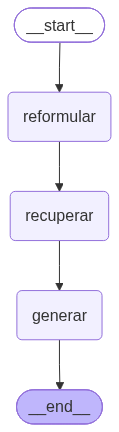

In [32]:
grafo = StateGraph(EstadoAgente)

grafo.add_node("reformular", nodo_reformular)
grafo.add_node("recuperar", nodo_recuperar)
grafo.add_node("generar", nodo_generar)

grafo.add_edge(START, "reformular")
grafo.add_edge("reformular", "recuperar")
grafo.add_edge("recuperar", "generar")
grafo.add_edge("generar", END)

agente_sin_memoria = grafo.compile()

try:
    display(Image(agente_sin_memoria.get_graph().draw_mermaid_png(max_retries=5, retry_delay=2.0)))
except Exception:
    print("⚠️ No se ha podido generar la imagen del grafo (servicio externo no disponible). Definición del grafo:\n")
    print(agente_sin_memoria.get_graph().draw_mermaid())    # Definición del grafo en texto, generada sin conexión

Construyo el grafo con `StateGraph`, indicándole el estado que comparten los nodos. Añado los tres nodos y los conecto con aristas en secuencia: el flujo empieza en `START`, pasa por la reformulación, la recuperación y la generación, y termina en `END`.

He optado por un flujo **lineal**, en el que la recuperación se ejecuta siempre, porque mi asistente es un experto que debe fundamentar todas sus respuestas en la base de conocimiento. Incluso en las preguntas fuera de su ámbito, recuperar contexto y dejar que el system prompt decida cómo responder garantiza un comportamiento coherente y controlado.

Compilo el grafo sin memoria e intento mostrar su diagrama con `draw_mermaid_png`. Este método no genera la imagen localmente, sino que la solicita a un servicio web externo, por lo que lo ejecuto con varios reintentos y dentro de un bloque `try/except`: si el servicio no está disponible, la celda no se interrumpe y muestro en su lugar la definición del grafo en formato texto, que se genera sin conexión. La visualización no influye en el funcionamiento del agente, que queda listo en el momento de compilar el grafo.

Para garantizar que el diagrama esté siempre disponible, incluyo también una imagen generada a partir de esa misma definición:

![Grafo del agente](img/grafo_agente.png)

In [33]:
def preguntar(agente, pregunta: str, config: dict = None):
    """Envía una pregunta al agente y muestra su respuesta"""
    print(f"\n👤 Pregunta: {pregunta}")
    print("-" * 90)

    resultado = agente.invoke({"messages": [HumanMessage(content=pregunta)]}, config=config)

    print("-" * 90)
    print(f"🤖 Respuesta:\n{resultado['messages'][-1].text}")
    print("=" * 90)
    return resultado

resultado_prueba = preguntar(agente_sin_memoria, "¿Qué se considera un gran incendio forestal y cuántos hubo en España en 2022?")


👤 Pregunta: ¿Qué se considera un gran incendio forestal y cuántos hubo en España en 2022?
------------------------------------------------------------------------------------------
[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Qué se considera un gran incendio forestal y cuántos hubo en España en 2022?
[NODO RECUPERAR] Documentos recuperados: 5
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_general | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
[NODO GENERAR] Respuesta generada
------------------------------------------------------------------------------------------
🤖 Respuesta:
Se considera un gran incendio forestal aquel que quema **500 hectáreas o más**. 

En España, durante el año **2022**, se registraron **56** grandes incendios forestales.

📚 Fuentes:
- Estadística General de Incendios Forestales, registros 1968-2022


Defino la función `preguntar`, que envía una pregunta al agente y muestra tanto el recorrido por los nodos como la respuesta final. Admite un parámetro `config` que todavía no utilizo, pero que necesitaré en la sección 8 para indicar a qué conversación pertenece cada pregunta. Guardo el resultado en una variable para que el notebook no muestre el estado completo del grafo, sino solo la traza y la respuesta.

Para la primera prueba he elegido una pregunta compuesta, que pide a la vez una definición y un dato concreto. El agente recupera el resumen del año 2022 y el resumen general generados a partir del CSV, que contienen tanto el criterio de gran incendio forestal (500 hectáreas o más) como el número de grandes incendios de ese año, y responde correctamente a las dos partes de la pregunta citando su fuente.

Esta prueba me permite comprobar además que el agente **no inventa información**: aunque la definición de gran incendio forestal también aparece en el informe del Decenio, el modelo no la ha mencionado porque ese fragmento no estaba entre los documentos recuperados, y solo cita la fuente que realmente ha utilizado.

In [34]:
pregunta_stream = "¿Cuál es la principal causa de los incendios forestales en Andalucía?"

for paso in agente_sin_memoria.stream({"messages": [HumanMessage(content=pregunta_stream)]}):
    for nombre_nodo, actualizacion in paso.items():
        print(f"\n✅ Nodo ejecutado: {nombre_nodo} | Campos actualizados: {list(actualizacion.keys())}")

print(f"\n🤖 Respuesta final:\n{actualizacion['messages'][-1].text}")

[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Cuál es la principal causa de los incendios forestales en Andalucía?

✅ Nodo ejecutado: reformular | Campos actualizados: ['pregunta_busqueda']
[NODO RECUPERAR] Documentos recuperados: 5
   - csv_resumen_comunidad | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv

✅ Nodo ejecutado: recuperar | Campos actualizados: ['contexto']
[NODO GENERAR] Respuesta generada

✅ Nodo ejecutado: generar | Campos actualizados: ['messages']

🤖 Respuesta final:
En Andalucía, según los registros del periodo 1968-2022, la principal causa de los incendios forestales es la **desconocida**, que representa el **35,0 %** de los casos. Le siguen de cerca los incendios **intencionados** (29,0 %) y las **negligencias** (27,3 %).

📚 Fuentes: Estadística General de Incendios Forestales, registros 1968-2022


Además de `invoke`, que devuelve únicamente el estado final, LangGraph permite ejecutar el grafo con `stream`, que devuelve la actualización que produce **cada nodo en el momento en que termina**. Lo utilizo para trazar el recorrido de una pregunta paso a paso y comprobar qué campos del estado modifica cada nodo: `reformular` actualiza `pregunta_busqueda`, `recuperar` actualiza `contexto` y `generar` añade la respuesta a `messages`.

Esta forma de ejecución resulta muy útil para depurar el agente, ya que si una respuesta no es correcta puedo identificar en qué paso del flujo se ha producido el problema. Como el último nodo en ejecutarse es `generar`, la última actualización contiene la respuesta final del agente.

# 8. Memoria de conversación

Un modelo de lenguaje no tiene memoria por sí mismo: cada llamada es independiente y el modelo solo conoce los mensajes que se le envían en ese momento. Para que mi asistente pueda mantener una conversación coherente, necesito guardar el historial de mensajes entre un turno y el siguiente y volver a proporcionárselo en cada pregunta.

En esta sección primero demuestro el problema con el agente sin memoria de la sección 7, después añado la memoria mediante un *checkpointer* de LangGraph y, por último, compruebo que el agente recuerda el contexto de la conversación, que mantiene separadas conversaciones distintas y que puedo inspeccionar el historial guardado.

In [35]:
resultado_1 = preguntar(agente_sin_memoria, "¿Cuál fue el mayor incendio forestal registrado en España?")
resultado_2 = preguntar(agente_sin_memoria, "¿Cuántas personas participaron en su extinción y cuánto se tardó en extinguirlo?")


👤 Pregunta: ¿Cuál fue el mayor incendio forestal registrado en España?
------------------------------------------------------------------------------------------
[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Cuál fue el mayor incendio forestal registrado en España?
[NODO RECUPERAR] Documentos recuperados: 5
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_general | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
[NODO GENERAR] Respuesta generada
------------------------------------------------------------------------------------------
🤖 Respuesta:
El mayor incendio forestal registrado en España (según los registros del periodo 1968-2022) se produjo el **27 de julio de 2004** en **Minas de Riotinto** (Huelva, Andalucía). 

* **Superficie quemada:** 29.867,0 hectáreas.
* **Causa:** Intencionado.

📚 Fuentes:
- Estadística General de Incendios Forestales, registros 1968-2022

👤 Pregunta:

Hago dos preguntas consecutivas al agente sin memoria. La segunda es una pregunta de seguimiento que solo tiene sentido si se recuerda la primera: *"su extinción"* se refiere al incendio mencionado en la respuesta anterior.

Como el agente se compiló sin memoria, cada llamada a `invoke` empieza con un estado vacío. En la segunda pregunta, el nodo de reformulación interpreta que se trata del primer turno de la conversación (no hay mensajes anteriores), busca en ChromaDB con la frase literal y el modelo no tiene forma de saber a qué incendio me refiero, por lo que no puede responder correctamente. Este es exactamente el problema que resuelve la memoria.

In [36]:
checkpointer = InMemorySaver()

agente = grafo.compile(checkpointer=checkpointer)
config_conversacion_1 = {"configurable": {"thread_id": "conversacion-1"}}

print("✅ Agente con memoria compilado")

✅ Agente con memoria compilado


Añado la memoria al agente compilando de nuevo el mismo grafo, esta vez con un **checkpointer**. `InMemorySaver` guarda el estado del grafo al terminar cada ejecución, de modo que en la siguiente pregunta de la misma conversación el estado no empieza vacío, sino con todos los mensajes anteriores. Gracias a que el estado está basado en `MessagesState`, cada pregunta y cada respuesta nuevas se **añaden** al historial guardado en lugar de sustituirlo.

Para identificar cada conversación utilizo un **`thread_id`**, que indico en la configuración de cada llamada. Todas las preguntas enviadas con el mismo `thread_id` comparten historial, mientras que un `thread_id` distinto inicia una conversación nueva e independiente.

In [37]:
resultado_1 = preguntar(agente, "¿Cuál fue el mayor incendio forestal registrado en España?", config=config_conversacion_1)
resultado_2 = preguntar(agente, "¿Cuántas personas participaron en su extinción y cuánto se tardó en extinguirlo?", config=config_conversacion_1)
resultado_3 = preguntar(agente, "¿Y cuáles son las causas más frecuentes de los incendios en esa comunidad?", config=config_conversacion_1)


👤 Pregunta: ¿Cuál fue el mayor incendio forestal registrado en España?
------------------------------------------------------------------------------------------
[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Cuál fue el mayor incendio forestal registrado en España?
[NODO RECUPERAR] Documentos recuperados: 5
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_general | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
[NODO GENERAR] Respuesta generada
------------------------------------------------------------------------------------------
🤖 Respuesta:
El mayor incendio forestal registrado en España (según los registros del periodo 1968-2022) se produjo el **27 de julio de 2004** en **Minas de Riotinto** (Huelva, Andalucía). 

* **Superficie quemada:** 29.867,0 hectáreas.
* **Causa:** Intencionado.

📚 Fuentes: Estadística General de Incendios Forestales, registros 1968-2022

👤 Pregunta: ¿

Repito la misma conversación con el agente con memoria, enviando todas las preguntas con el mismo `thread_id`, y añado una tercera pregunta de seguimiento:

1. **Primera pregunta:** el agente identifica el mayor incendio registrado (el de Minas de Riotinto, en Huelva, en 2004).
2. **Segunda pregunta:** gracias a la memoria, el nodo de reformulación dispone del historial y reescribe *"su extinción"* como una pregunta sobre el incendio de Minas de Riotinto. De este modo, la búsqueda recupera la ficha de ese incendio y el agente puede responder con el personal de extinción y la duración.
3. **Tercera pregunta:** el agente debe resolver una referencia todavía más indirecta, ya que *"esa comunidad"* no aparece en la pregunta anterior, sino que se deduce de la ubicación del incendio (Andalucía). Si la reformulación lo resuelve correctamente, la búsqueda recuperará el resumen de Andalucía.

En la traza de cada pregunta se puede ver la pregunta original y la pregunta reformulada que se utiliza para buscar, lo que demuestra cómo la memoria y la reformulación trabajan juntas para que la búsqueda en la base de conocimiento siga siendo precisa a lo largo de la conversación.

In [38]:
config_conversacion_2 = {"configurable": {"thread_id": "conversacion-2"}}

resultado_otro_hilo = preguntar(agente, "¿Cuántas personas participaron en su extinción?", config=config_conversacion_2)
resultado_vuelta = preguntar(agente, "Recuérdame de qué incendio estábamos hablando.", config=config_conversacion_1)


👤 Pregunta: ¿Cuántas personas participaron en su extinción?
------------------------------------------------------------------------------------------
[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Cuántas personas participaron en su extinción?
[NODO RECUPERAR] Documentos recuperados: 5
   - pdf | incendios-decenio-2006-2015_tcm30-521617.pdf
   - csv_gran_incendio | fires-all.csv
   - csv_gran_incendio | fires-all.csv
   - pdf | incendios-decenio-2006-2015_tcm30-521617.pdf
   - csv_gran_incendio | fires-all.csv
[NODO GENERAR] Respuesta generada
------------------------------------------------------------------------------------------
🤖 Respuesta:
No dispongo de información sobre a qué incendio te refieres en tu pregunta. Por favor, indícame de qué incendio o periodo deseas conocer el dato. 

Como referencia, puedo informarte sobre las personas que participaron en la extinción de incendios específicos incluidos en las fichas del periodo 1968-2022, como:
- El incendio de **A

Compruebo que las conversaciones se mantienen **aisladas** entre sí:

- **En una conversación nueva** (`conversacion-2`) hago la misma pregunta de seguimiento que antes. Como este hilo no tiene historial, el agente no sabe a qué incendio me refiero, igual que le ocurría al agente sin memoria.
- **Al volver a la primera conversación** (`conversacion-1`), el agente sigue recordando que estábamos hablando del incendio de Minas de Riotinto.

Este comportamiento es el que permite que varios usuarios conversen con el asistente a la vez sin que se mezclen sus historiales, algo que aprovecharé en la interfaz de Streamlit asignando un identificador de conversación a cada sesión.

In [39]:
estado = agente.get_state(config_conversacion_1)
mensajes_guardados = estado.values["messages"]

print(f"📋 Historial de la conversación 1: {len(mensajes_guardados)} mensajes\n")
for i, mensaje in enumerate(mensajes_guardados, start=1):
    rol = "👤 Usuario" if mensaje.__class__.__name__ == "HumanMessage" else "🤖 Asistente"
    print(f"[{i}] {rol}: {mensaje.text[:120]}...")
print(f"\n🔎 Última pregunta reformulada: {estado.values['pregunta_busqueda']}")

📋 Historial de la conversación 1: 8 mensajes

[1] 👤 Usuario: ¿Cuál fue el mayor incendio forestal registrado en España?...
[2] 🤖 Asistente: El mayor incendio forestal registrado en España (según los registros del periodo 1968-2022) se produjo el **27 de julio ...
[3] 👤 Usuario: ¿Cuántas personas participaron en su extinción y cuánto se tardó en extinguirlo?...
[4] 🤖 Asistente: En la extinción del incendio de Minas de Riotinto de 2004 participaron **1.504 personas** y se tardó **184,4 horas** en ...
[5] 👤 Usuario: ¿Y cuáles son las causas más frecuentes de los incendios en esa comunidad?...
[6] 🤖 Asistente: Las causas principales de los incendios forestales en Andalucía (según los registros del periodo 1968-2022) son:

* **De...
[7] 👤 Usuario: Recuérdame de qué incendio estábamos hablando....
[8] 🤖 Asistente: Estábamos hablando del incendio de **Minas de Riotinto** (Huelva, Andalucía), declarado el 27 de julio de 2004, que fue ...

🔎 Última pregunta reformulada: ¿De qué incendio estábam

Inspecciono con `get_state` el estado que el checkpointer ha guardado para la primera conversación. Muestro el número de mensajes almacenados y el comienzo de cada uno, alternando entre las preguntas del usuario y las respuestas del asistente, lo que confirma que el historial completo se conserva entre turnos.

Además del historial, el estado guardado incluye los campos propios que definí en la sección 7, como la última pregunta reformulada, lo que me permite revisar cómo ha interpretado el agente cada pregunta. Observo también que el historial **no contiene el system prompt ni el contexto recuperado**, sino únicamente los mensajes de la conversación, tal y como diseñé el nodo de generación.

# 9. Batería de preguntas de ejemplo

En esta sección evalúo el comportamiento del asistente con una batería de preguntas representativas de los distintos usos que puede tener. He diseñado las preguntas para que, en conjunto, pongan a prueba **todas las fuentes** de la base de conocimiento y **todas las situaciones** previstas en el system prompt:

| Nº | Categoría | Qué compruebo |
|---|---|---|
| 1 | Conceptos y metodología | Que responde a preguntas conceptuales con el informe del Decenio |
| 2 | Evolución histórica | Que responde a preguntas globales con el resumen general del CSV |
| 3 | Distribución territorial | Que localiza los datos de una comunidad concreta |
| 4 | Causas | Que combina información del CSV y del informe del Decenio |
| 5 | Grandes incendios | Que recupera la ficha de un incendio concreto |
| 6 | Emergencia y autoprotección | Que aplica el protocolo de emergencia (112) y los consejos de Protección Civil |
| 7 | Límites de la base de conocimiento | Que reconoce que no dispone de datos posteriores a 2022 en lugar de inventarlos |

Cada pregunta se envía en una conversación independiente (con su propio `thread_id`), de forma que las respuestas no se vean influidas por las preguntas anteriores y cada una refleje el comportamiento del asistente ante una consulta aislada.

In [40]:
PREGUNTAS_EJEMPLO = [
    {"categoria": "Conceptos y metodología",
     "pregunta": "¿Cuál es la diferencia entre un conato y un incendio forestal?"},
    {"categoria": "Evolución histórica",
     "pregunta": "¿Cuál fue el peor año de incendios forestales en España en superficie quemada?"},
    {"categoria": "Distribución territorial",
     "pregunta": "¿Qué provincia de Galicia ha tenido más superficie quemada por incendios forestales?"},
    {"categoria": "Causas",
     "pregunta": "¿Por qué se provocan los incendios intencionados en España?"},
    {"categoria": "Grandes incendios",
     "pregunta": "¿Qué ocurrió en el incendio de Cortes de Pallás de 2012?"},
    {"categoria": "Emergencia y autoprotección",
     "pregunta": "Estoy de excursión por el monte y veo una columna de humo cerca, ¿qué hago?"},
    {"categoria": "Límites de la base de conocimiento",
     "pregunta": "¿Cuántas hectáreas se quemaron en España en 2024?"}
]

respuestas_bateria = []

for i, ejemplo in enumerate(PREGUNTAS_EJEMPLO, start=1):
    print(f"\n\n📌 Ejemplo {i} - {ejemplo['categoria'].upper()}")
    config_ejemplo = {"configurable": {"thread_id": f"bateria-{i}"}}

    resultado = preguntar(agente, ejemplo["pregunta"], config=config_ejemplo)

    respuestas_bateria.append({
        "categoria": ejemplo["categoria"],
        "pregunta": ejemplo["pregunta"],
        "respuesta": resultado["messages"][-1].text
    })



📌 Ejemplo 1 - CONCEPTOS Y METODOLOGÍA

👤 Pregunta: ¿Cuál es la diferencia entre un conato y un incendio forestal?
------------------------------------------------------------------------------------------
[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Cuál es la diferencia entre un conato y un incendio forestal?
[NODO RECUPERAR] Documentos recuperados: 5
   - pdf | Estadística-General-IF-Metodología.pdf
   - pdf | incendios-decenio-2006-2015_tcm30-521617.pdf
   - pdf | incendios-decenio-2006-2015_tcm30-521617.pdf
   - pdf | incendios-decenio-2006-2015_tcm30-521617.pdf
   - pdf | Estadística-General-IF-Metodología.pdf
[NODO GENERAR] Respuesta generada
------------------------------------------------------------------------------------------
🤖 Respuesta:
La diferencia principal entre ambos términos según la superficie afectada es la siguiente:

* **Conato:** Es aquel siniestro que afecta a una superficie menor o igual a 1 hectárea ($\le 1\text{ ha}$).
* **Incendio:** Es aqu

Defino las siete preguntas de ejemplo junto con su categoría y las envío una a una al agente con memoria, asignando a cada una un `thread_id` propio (`bateria-1`, `bateria-2`…) para que se procesen como conversaciones independientes.

Para cada pregunta se muestra la traza completa del agente (la pregunta que utiliza para buscar, los documentos recuperados y su tipo) y la respuesta final. Además, guardo la categoría, la pregunta y la respuesta de cada ejemplo en una lista, que utilizo a continuación para construir una tabla resumen de la batería.

In [41]:
df_bateria = pd.DataFrame(respuestas_bateria)

df_bateria["fuentes_citadas"] = [
    r.split("📚 Fuentes:")[-1].strip() if "📚 Fuentes:" in r else "Sin fuentes (no aplica)" for r in df_bateria["respuesta"]
]
df_bateria["palabras"] = [len(r.split()) for r in df_bateria["respuesta"]]

df_bateria[["categoria", "pregunta", "fuentes_citadas", "palabras"]]

,categoria,pregunta,fuentes_citadas,palabras
0,Conceptos y metodología,¿Cuál es la diferencia entre un conato y un in...,- Metodología de la Estadística General de Inc...,92
1,Evolución histórica,¿Cuál fue el peor año de incendios forestales ...,"Estadística General de Incendios Forestales, r...",67
2,Distribución territorial,¿Qué provincia de Galicia ha tenido más superf...,"Estadística General de Incendios Forestales, r...",53
3,Causas,¿Por qué se provocan los incendios intencionad...,- Los Incendios Forestales en España. Decenio ...,121
4,Grandes incendios,¿Qué ocurrió en el incendio de Cortes de Pallá...,"Estadística General de Incendios Forestales, r...",87
5,Emergencia y autoprotección,Estoy de excursión por el monte y veo una colu...,Consejos ante incendios forestales (Protección...,119
6,Límites de la base de conocimiento,¿Cuántas hectáreas se quemaron en España en 2024?,Sin fuentes (no aplica),40


Reúno los resultados de la batería en una tabla resumen con la categoría y la pregunta de cada ejemplo, las fuentes que el asistente ha citado en su respuesta y la longitud de la respuesta en palabras.

Esta tabla me permite verificar de un vistazo dos aspectos del comportamiento que definí en el system prompt: que el asistente **cita las fuentes** cuando utiliza información de la base de conocimiento (y no las cita cuando no dispone de ella) y que **respeta el límite de longitud** de 200 palabras.

### Análisis de los resultados

El asistente ha respondido correctamente a las siete preguntas de la batería, recuperando en cada caso la fuente adecuada y respetando las instrucciones del system prompt. Analizo cada ejemplo:

1. **Conceptos y metodología:** recupera exclusivamente documentos PDF (el informe del Decenio y la metodología de la Estadística General) y explica con precisión la diferencia: un conato afecta a 1 hectárea o menos y un incendio a más de 1 hectárea. Cita los dos documentos en los que aparece la definición, con la página exacta de cada uno.

2. **Evolución histórica:** identifica 1985 como el peor año, con 483.844 hectáreas quemadas, gracias al resumen general generado a partir del CSV, y completa la respuesta con el resto de años más graves del periodo 1968-2022. Es un ejemplo de pregunta global que el RAG no podría resolver con documentos sueltos y que se resuelve gracias al preprocesado de los datos con pandas.

3. **Distribución territorial:** recupera en primer lugar el resumen de Galicia y responde que Ourense es la provincia con más superficie quemada (730.111 ha), seguida de Pontevedra y Lugo.

4. **Causas:** es la respuesta más completa, ya que **combina las dos fuentes de la base de conocimiento**: las motivaciones más frecuentes del periodo 1968-2022 procedentes del CSV y las motivaciones adicionales que recoge el informe del Ministerio para el decenio 2006-2015 (como la quema agrícola ilegal, las venganzas o la modificación del uso del suelo). El asistente distingue claramente ambos periodos en lugar de mezclarlos, tal y como le indica la instrucción 3 del system prompt, y cita las dos fuentes.

5. **Grandes incendios:** recupera la ficha del incendio de Cortes de Pallás y ofrece todos sus datos: fecha, superficie (28.879,1 ha), causa y causa detallada, víctimas, personal de extinción y duración. Además, combina la ficha con el resumen anual y el de la Comunitat Valenciana para contextualizarlo como el mayor incendio de 2012 en España y el mayor registrado en esa comunidad.

6. **Emergencia y autoprotección:** aplica el protocolo de emergencia definido en el system prompt, indicando en primer lugar que se llame al 112, y a continuación ofrece las pautas de autoprotección de Protección Civil (alejarse por los laterales, ir en contra del viento, evitar barrancos y no huir ladera arriba). La recomendación del 112 no aparece en los documentos recuperados, sino que procede de la instrucción 6 del prompt, lo que demuestra que el asistente prioriza la seguridad del usuario en situaciones de riesgo.

7. **Límites de la base de conocimiento:** aunque la búsqueda recupera resúmenes de otros años, el asistente reconoce que no dispone de datos de 2024 en lugar de inventarlos o de ofrecer las cifras de otro año. Además, orienta al usuario sobre el tipo de información que sí puede consultar y omite la línea de fuentes, ya que no ha utilizado ninguna.

La tabla resumen confirma que el asistente **cita sus fuentes** en todas las respuestas basadas en la base de conocimiento, que **no las cita** cuando no dispone de la información y que todas las respuestas se mantienen **por debajo del límite de 200 palabras** (entre 53 y 121 palabras).

# 10. Celda de chat interactiva

En esta sección habilito una celda para conversar con el asistente de forma interactiva desde el propio notebook. Cada mensaje que escribo se envía al agente con memoria y su respuesta se muestra inmediatamente, de modo que puedo mantener una conversación completa con preguntas de seguimiento.

La celda admite dos comandos especiales:

- **`nueva`:** inicia una conversación nueva, con un historial vacío.
- **`salir`:** finaliza el chat.

In [42]:
def iniciar_chat():
    """Abre un chat interactivo con el asistente hasta que el usuario escriba 'salir'"""
    config_chat = {"configurable": {"thread_id": f"chat-{int(time.time())}"}}   # Identificador único basado en la hora actual

    print("🔥 Asistente Experto en Incendios Forestales en España")
    print("Escribe tu pregunta. Comandos: 'nueva' para empezar otra conversación, 'salir' para terminar.\n")

    while True:
        pregunta = input("👤 Tú: ").strip()

        if not pregunta:
            continue
        if pregunta.lower() in ["salir", "exit", "quit"]:
            print("\n👋 ¡Hasta pronto! Recuerda: ante cualquier incendio, llama al 112.")
            break
        if pregunta.lower() == "nueva":
            config_chat = {"configurable": {"thread_id": f"chat-{int(time.time())}"}}
            print("\n🆕 Nueva conversación iniciada. El historial anterior se ha descartado.\n")
            continue

        print(f"\n👤 Tú: {pregunta}")
        resultado = agente.invoke({"messages": [HumanMessage(content=pregunta)]}, config=config_chat)
        print(f"\n🤖 Asistente:\n{resultado['messages'][-1].text}\n")
        print("-" * 90)

iniciar_chat()

🔥 Asistente Experto en Incendios Forestales en España
Escribe tu pregunta. Comandos: 'nueva' para empezar otra conversación, 'salir' para terminar.


👤 Tú: ¿Cuál fue el mayor incendio de 2022?
[NODO REFORMULAR] Primer turno, uso la pregunta original: ¿Cuál fue el mayor incendio de 2022?
[NODO RECUPERAR] Documentos recuperados: 5
   - csv_resumen_anual | fires-all.csv
   - csv_resumen_anual | fires-all.csv
   - csv_gran_incendio | fires-all.csv
   - csv_gran_incendio | fires-all.csv
   - csv_gran_incendio | fires-all.csv
[NODO GENERAR] Respuesta generada

🤖 Asistente:
El mayor incendio de 2022 se produjo el 17 de julio en **Losacio (Zamora, Castilla y León)**, quemando una superficie de **23.611,5 hectáreas**. Su causa fue un rayo.

📚 Fuentes: Estadística General de Incendios Forestales, registros 1968-2022

------------------------------------------------------------------------------------------

👤 Tú: ¿Cuál fue su causa?
[NODO REFORMULAR] Pregunta original: ¿Cuál fue su causa?
[NODO 

Defino la función `iniciar_chat`, que abre un bucle de conversación en el que leo cada mensaje con `input` y lo envío al agente con memoria hasta que escribo `salir`.

Al iniciar el chat genero un **`thread_id` único** a partir de la hora actual, de modo que cada sesión de chat es una conversación independiente que no se mezcla con las conversaciones de prueba de las secciones anteriores. Dentro de una misma sesión, todas las preguntas comparten ese identificador, por lo que el agente recuerda el contexto de la conversación y puedo hacer preguntas de seguimiento. Con el comando `nueva` genero un identificador distinto y empiezo una conversación desde cero, sin necesidad de volver a ejecutar la celda.

Además, ignoro los mensajes vacíos para no realizar llamadas innecesarias a la API, y muestro cada pregunta junto a su respuesta para que la conversación quede registrada en la salida de la celda.

A continuación incluyo un ejemplo de conversación realizada con esta celda, en la que se puede comprobar cómo el asistente mantiene el contexto entre preguntas.

# 11. Conclusiones

En este proyecto he construido un asistente conversacional experto en incendios forestales en España que responde a preguntas en lenguaje natural basándose en una base de conocimiento propia. El sistema integra todas las piezas de una aplicación de IA Generativa:

- **Base de conocimiento vectorial:** he combinado tres documentos PDF (el informe del Decenio 2006-2015, la metodología de la Estadística General de Incendios Forestales y los consejos de Protección Civil) con un dataset de casi 300.000 incendios registrados entre 1968 y 2022. En total, 633 documentos indexados en ChromaDB con el modelo de embeddings de Gemini.
- **Preprocesado de datos con pandas:** en lugar de indexar el CSV fila a fila, lo he transformado en resúmenes generales, anuales y por comunidad autónoma, y en fichas de los grandes incendios, traduciendo además los códigos de causa y subcausa a lenguaje natural. Este paso es el que permite al asistente responder a preguntas que requieren agregar todo el dataset.
- **Ingeniería de prompts:** he diseñado un system prompt que aplica técnicas como el patrón persona, la verificación de condiciones, los filtros semánticos o los delimitadores, y que obliga al modelo a basarse únicamente en el contexto recuperado y a citar siempre sus fuentes.
- **Agente en LangGraph:** he modelado el flujo como un grafo de tres nodos (reformular, recuperar y generar) que comparten un estado común.
- **Memoria de conversación:** mediante un checkpointer y un identificador de conversación, el agente recuerda el historial y responde correctamente a preguntas de seguimiento, manteniendo aisladas las distintas conversaciones.

Las pruebas realizadas demuestran que el asistente recupera la fuente adecuada para cada tipo de pregunta, combina información de varias fuentes sin mezclar sus periodos de referencia, reconoce cuándo no dispone de la información en lugar de inventarla y aplica un protocolo de emergencia cuando la consulta lo requiere.

## 💡 Decisiones técnicas y aprendizajes

A lo largo del desarrollo, varias pruebas me han llevado a modificar el diseño inicial. Considero que estas decisiones son una parte importante del proyecto:

- **La forma de los documentos condiciona la búsqueda.** Inicialmente titulé las fichas de los grandes incendios como *"GRAN INCENDIO FORESTAL DE…"*. Al probar la búsqueda comprobé que, ante una pregunta conceptual sobre qué es un gran incendio forestal, las fichas acaparaban todos los resultados por repetir esa expresión. Cambiar los títulos solucionó el problema, lo que demuestra que en un sistema RAG la redacción de los documentos es tan importante como el modelo.
- **La memoria por sí sola no basta en un sistema RAG.** El modelo entiende una pregunta como *"¿cuál fue su causa?"* gracias al historial, pero la búsqueda en ChromaDB no. Por eso añadí el nodo de reformulación, que convierte cada pregunta en una consulta autónoma. Además, al detectar que el modelo descartaba documentos válidos porque la pregunta literal no los mencionaba, incorporé también la pregunta reformulada al system prompt.
- **El contexto recuperado puede contener ruido.** El retriever devuelve siempre cinco documentos, y no todos son relevantes. Añadí una instrucción específica para que el modelo descarte los que no se refieren a lo que se pregunta.
- **Los límites de la API forman parte del diseño.** La cuota gratuita de embeddings de Gemini (30.000 tokens por minuto y 1.000 peticiones diarias) me obligó a indexar en lotes pequeños con reintentos, a ajustar el tamaño de los chunks y el umbral de las fichas para reducir el número de documentos, y a guardar la base vectorial en disco para generarla una sola vez.
- **Cada modelo tiene sus particularidades.** Los modelos Gemini 3.5 no permiten modificar la temperatura y devuelven el contenido en bloques, lo que me llevó a controlar la precisión de las respuestas mediante el prompt y a leer las respuestas con `.text`.

## ⚠️ Limitaciones y posibles mejoras

Soy consciente de que el asistente tiene algunas limitaciones, que señalo junto con las mejoras que aplicaría en una siguiente versión:

| Limitación | Posible mejora |
|---|---|
| Los datos estadísticos llegan hasta 2022 y el informe analiza el decenio 2006-2015 | Incorporar los informes y avances estadísticos más recientes del Ministerio |
| Solo dispongo de fichas individuales para los incendios de 3.000 hectáreas o más | Ampliar el número de fichas con una cuota de API mayor |
| La base de conocimiento no incluye normativa | Añadir la Ley de Montes y la normativa autonómica de prevención de incendios |
| El retriever recupera siempre cinco documentos por similitud, sin filtrar por año o comunidad | Aprovechar los metadatos que ya incluyen los documentos para filtrar la búsqueda según la pregunta |
| La memoria (`InMemorySaver`) se pierde al reiniciar el kernel | Utilizar un checkpointer persistente respaldado por una base de datos |
| He evaluado las respuestas revisándolas manualmente | Automatizar la evaluación con un LLM que actúe como juez sobre un conjunto de preguntas de referencia |

Como complemento al notebook, he desarrollado una interfaz web con Streamlit que permite conversar con el asistente desde el navegador, reutilizando la misma base de conocimiento, el mismo system prompt y el mismo agente de LangGraph.